# Final Project Data
Angelic McPherson

In [2]:
# Imports for assignment 
import numpy as np
import pandas as pd
import igraph as ig

In [2]:
# Load in the twitch dataset

# Grab datasets
edges_df = pd.read_csv('/Users/angelicmcpherson/Documents/QSS_41/PS4/twitch_gamers/large_twitch_edges.csv')
features_df = pd.read_csv('/Users/angelicmcpherson/Documents/QSS_41/PS4/twitch_gamers/large_twitch_features.csv')

# Grab all nodes
nodes = features_df['numeric_id'].unique()
print(len(nodes)) #check that it matches 168,114

# Load graph
twitch_g = ig.Graph(n = len(nodes), directed=False)

168114


In [3]:
# Assign all nodes attributes 
twitch_g.vs['name'] = nodes.tolist()

# Set numeric_id as the index for easier lookup
features_df.set_index('numeric_id', inplace=True)

for v in twitch_g.vs:
    node_id = v['name']  # now the numeric_id 
    if node_id in features_df.index:
        features = features_df.loc[node_id]
        for feature, value in features.items():
            v[feature] = value

In [4]:
display(edges_df.head())

# Add all edges to graph
edges = [(row['numeric_id_1'], row['numeric_id_2']) for idx, row in edges_df.iterrows()]
print(edges[:10])

twitch_g.add_edges(edges)

,numeric_id_1,numeric_id_2
0,98343,141493
1,98343,58736
2,98343,140703
3,98343,151401
4,98343,157118


[(98343, 141493), (98343, 58736), (98343, 140703), (98343, 151401), (98343, 157118), (98343, 125430), (98343, 3635), (98343, 495), (98343, 116648), (98343, 1679)]


In [5]:
# Create function to make column for variable attributes
def add_attr_col(attribute, attr_df):
    attr_dict = {v['name']: v[attribute] for v in twitch_g.vs}
    attr_df[f'{attribute}_1'] = attr_df['numeric_id_1'].map(attr_dict)
    attr_df[f'{attribute}_2'] = attr_df['numeric_id_2'].map(attr_dict)
    return attr_df

In [6]:
twitch_df = edges_df.copy()

node_attributes = ['created_at', 'updated_at', 'life_time', 'views','dead_account', 'language', 'affiliate', 'mature',]
for attr in node_attributes:
    print(attr)
    attr_df = add_attr_col(attr, twitch_df)
    twitch_df = attr_df

display(twitch_df)

created_at
updated_at
life_time
views
dead_account
language
affiliate
mature


,numeric_id_1,numeric_id_2,created_at_1,created_at_2,updated_at_1,updated_at_2,life_time_1,life_time_2,views_1,views_2,dead_account_1,dead_account_2,language_1,language_2,affiliate_1,affiliate_2,mature_1,mature_2
0,98343,141493,2012-12-27,2008-02-13,2018-09-13,2018-10-12,2086,3894,282,42340657,0,0,EN,EN,0,0,0,0
1,98343,58736,2012-12-27,2013-01-07,2018-09-13,2018-10-12,2086,2104,282,72048,0,0,EN,EN,0,1,0,0
2,98343,140703,2012-12-27,2012-03-09,2018-09-13,2018-10-12,2086,2408,282,13949,0,0,EN,EN,0,1,0,1
3,98343,151401,2012-12-27,2014-07-16,2018-09-13,2018-10-12,2086,1549,282,36301,0,0,EN,EN,0,0,0,1
4,98343,157118,2012-12-27,2007-10-28,2018-09-13,2018-10-12,2086,4002,282,1197884,0,0,EN,EN,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6797552,97507,29359,2018-02-18,2013-07-20,2018-10-12,2018-10-12,236,1910,1471,6316,0,0,ES,ES,1,1,0,0
6797553,71175,12020,2014-05-24,2017-03-17,2018-10-11,2018-10-10,1601,572,368,486,0,0,EN,EN,0,0,0,1
6797554,151702,128281,2017-07-30,2014-04-30,2018-10-12,2018-10-01,439,1615,2552,866,0,0,EN,EN,1,0,1,0
6797555,118034,38021,2012-11-13,2016-11-27,2018-09-07,2018-10-06,2124,678,1688,417,0,0,EN,EN,0,0,1,1


In [7]:
final_twitch_df = twitch_df[(twitch_df['dead_account_1'] != 1) & (twitch_df['dead_account_2'] != 1)]
final_twitch_df = twitch_df[(twitch_df['language_1'] != 'OTHER') & (twitch_df['language_2'] != 'OTHER')]

print(f'Difference of {len(edges_df) - len(final_twitch_df)} edges')
print("Final length is", len(final_twitch_df))

Difference of 42011 edges
Final length is 6755546


In [8]:
final_twitch_df.to_csv('twitch_dataset.csv', sep='|', index=False)

## Split by Communities

In [22]:
twitch_df = pd.read_csv('twitch_dataset.csv', sep='|')

In [23]:
# Filter out English
new_twitch_df = twitch_df[(twitch_df['language_1'] != 'EN') & (twitch_df['language_2'] != 'EN')].copy()

# Remove dead accounts
new_twitch_df = new_twitch_df[(new_twitch_df['dead_account_1'] != 1) & (new_twitch_df['dead_account_2'] != 1)]

# Filter out 'OTHER' language
new_twitch_df = new_twitch_df[(new_twitch_df['language_1'] != 'OTHER') & (new_twitch_df['language_2'] != 'OTHER')]

all_languages = set(pd.concat([new_twitch_df['language_1'], new_twitch_df['language_2']]).unique())
print(all_languages)

{'FI', 'PL', 'FR', 'ES', 'DA', 'NO', 'ZH', 'HU', 'NL', 'IT', 'PT', 'DE', 'RU', 'KO', 'CS', 'TR', 'SV', 'JA', 'TH'}


In [24]:
import numpy as np

# Suppose all_languages is a set of languages seen
palette = ['cadetblue', 'bisque', 'navy', 'darkgreen', 'coral', 'pink', 'darksalmon', 'dimgray', 'goldenrod', 'honeydew', 'lightpink', 'maroon', 'mistyrose', 'plum', 'seagreen', 'violet', 'yellowgreen', 'tomato', 'royalblue']
lang_to_color = {lang : palette[i] for i, lang in enumerate(all_languages)}

# edge color: black if same language, else red
new_twitch_df['edge_color'] = np.where(
    new_twitch_df['language_1'] == new_twitch_df['language_2'],
    'black',
    'magenta'
)

display(new_twitch_df.head())
print(len(new_twitch_df))

,numeric_id_1,numeric_id_2,created_at_1,created_at_2,updated_at_1,updated_at_2,life_time_1,life_time_2,views_1,views_2,dead_account_1,dead_account_2,language_1,language_2,affiliate_1,affiliate_2,mature_1,mature_2,edge_color
205778,147290,82054,2013-04-11,2014-05-21,2018-10-12,2018-10-12,2010,1605,334364,99945,0,0,NL,NL,0,0,1,0,black
205781,147290,2703,2013-04-11,2013-07-10,2018-10-12,2018-10-11,2010,1919,334364,1327,0,0,NL,NL,0,1,1,1,black
205798,147290,303,2013-04-11,2014-09-08,2018-10-12,2018-10-08,2010,1491,334364,8483,0,0,NL,NL,0,1,1,1,black
205801,147290,64642,2013-04-11,2014-03-25,2018-10-12,2018-10-12,2010,1662,334364,17851,0,0,NL,NO,0,1,1,1,magenta
205810,147290,95508,2013-04-11,2013-08-13,2018-10-12,2018-07-25,2010,1807,334364,2069,0,0,NL,NL,0,0,1,0,black


652877


In [25]:
features_df = pd.read_csv('/Users/angelicmcpherson/Documents/QSS_41/PS4/twitch_gamers/large_twitch_features.csv')
new_twitch_features = features_df[(features_df['dead_account'] != 1)].copy()
new_twitch_features = new_twitch_features[(new_twitch_features['language'] != 'OTHER')]
new_twitch_features = new_twitch_features[(new_twitch_features['language'] != 'EN')]


# community color according to language_1
new_twitch_features['community_color'] = new_twitch_features['language'].map(lang_to_color)
display(new_twitch_features.head())


,views,mature,life_time,created_at,updated_at,numeric_id,dead_account,language,affiliate,community_color
7,775,1,577,2017-03-14,2018-10-12,7,0,FR,0,navy
9,32073,0,499,2017-05-31,2018-10-12,9,0,KO,1,plum
12,2178,0,908,2016-04-16,2018-10-11,12,0,JA,0,tomato
14,2002,0,1910,2013-05-17,2018-08-09,14,0,RU,0,mistyrose
22,212680,1,2056,2013-02-24,2018-10-12,22,0,PL,0,bisque


In [26]:
# Save both files
new_twitch_df.to_csv('twitch_edges.csv', sep='|', index=False)
new_twitch_features.to_csv('twitch_features.csv', sep='|', index=False)

In [48]:
# Graph
nodes = list(set(new_twitch_df["numeric_id_1"]).union(set(new_twitch_df["numeric_id_2"])))
final_graph = ig.Graph(n=len(nodes), directed=False)
final_graph.vs["name"] = nodes

# Add edges
edge_tuples = list(zip(new_twitch_df["numeric_id_1"], new_twitch_df["numeric_id_2"]))
final_graph = ig.Graph.TupleList(edge_tuples, directed=False, vertex_name_attr="name")

In [ ]:
# Add color to vertices
id_to_color = dict(zip(nodes, new_twitch_features["community_color"]))
final_graph.vs["color"] = [id_to_color.get(v["name"], "gray") for v in final_graph.vs]


In [ ]:
# Add color to edges
final_graph.es["color"] = list(new_twitch_df["edge_color"])

### Lets look at every community

In [1]:
# Imports for assignment 
import numpy as np
import pandas as pd
import igraph as ig

In [27]:
twitch_nodes = pd.read_csv('twitch_features.csv', sep='|')
display(twitch_nodes.head())
twitch_edges = pd.read_csv('twitch_edges.csv', sep='|')
display(twitch_edges.head())

,views,mature,life_time,created_at,updated_at,numeric_id,dead_account,language,affiliate,community_color
0,775,1,577,2017-03-14,2018-10-12,7,0,FR,0,navy
1,32073,0,499,2017-05-31,2018-10-12,9,0,KO,1,plum
2,2178,0,908,2016-04-16,2018-10-11,12,0,JA,0,tomato
3,2002,0,1910,2013-05-17,2018-08-09,14,0,RU,0,mistyrose
4,212680,1,2056,2013-02-24,2018-10-12,22,0,PL,0,bisque


,numeric_id_1,numeric_id_2,created_at_1,created_at_2,updated_at_1,updated_at_2,life_time_1,life_time_2,views_1,views_2,dead_account_1,dead_account_2,language_1,language_2,affiliate_1,affiliate_2,mature_1,mature_2,edge_color
0,147290,82054,2013-04-11,2014-05-21,2018-10-12,2018-10-12,2010,1605,334364,99945,0,0,NL,NL,0,0,1,0,black
1,147290,2703,2013-04-11,2013-07-10,2018-10-12,2018-10-11,2010,1919,334364,1327,0,0,NL,NL,0,1,1,1,black
2,147290,303,2013-04-11,2014-09-08,2018-10-12,2018-10-08,2010,1491,334364,8483,0,0,NL,NL,0,1,1,1,black
3,147290,64642,2013-04-11,2014-03-25,2018-10-12,2018-10-12,2010,1662,334364,17851,0,0,NL,NO,0,1,1,1,magenta
4,147290,95508,2013-04-11,2013-08-13,2018-10-12,2018-07-25,2010,1807,334364,2069,0,0,NL,NL,0,0,1,0,black


In [28]:
chosen_lang = {'ES', 'FR', 'RU', 'ZH'} # compare with languages also with diverse speakers and countries

twitch_nodes = twitch_nodes[twitch_nodes['language'].isin(chosen_lang)]

print(len(twitch_nodes))

print(len(twitch_edges))

19770
652877


In [29]:
nodes = set(twitch_nodes['numeric_id'])

twitch_edges = twitch_edges[
    twitch_edges['numeric_id_1'].isin(nodes) & 
    twitch_edges['numeric_id_2'].isin(nodes)
]

print(len(twitch_edges))

323741


In [30]:
twitch_nodes.rename(columns={'community_color': 'color'}, inplace=True)
twitch_edges.rename(columns={'edge_color': 'color'}, inplace=True)

In [24]:

def get_community_g(lang):
    # Filter nodes and edges by language
    node_df = twitch_nodes[twitch_nodes['language'] == lang].copy()
    edge_df = twitch_edges[
        (twitch_edges['language_1'] == lang) & (twitch_edges['language_2'] == lang)
    ].copy()

    # Build igraph graph from edge list, set vertex name attribute
    edge_tuples = list(zip(edge_df["numeric_id_1"], edge_df["numeric_id_2"]))
    g = ig.Graph.TupleList(edge_tuples, directed=False, vertex_name_attr="name")

    # Assign node attributes to vertices by matching 'name' to node_df['numeric_id']
    # Create a mapping from numeric_id to attributes (dict or pandas Series)
    for col in ["views", "mature", "life_time", "created_at", "updated_at", "dead_account", "language", "affiliate", "color"]:
        attr_map = dict(zip(node_df["numeric_id"], node_df[col]))
        # For each vertex, assign attribute by vertex name
        g.vs[col] = [attr_map.get(v["name"], None) for v in g.vs]
        g.vs['size'] = 10

    # Assign edge colors
    # Make sure edges in g are in the same order as edge_df rows to align colors correctly
    # igraph TupleList preserves edge order as per `edge_tuples`, so safe to assign directly
    g.es['color'] = list(edge_df['color'])

    # Add community label
    g["community"] = lang

    return g

In [35]:
import matplotlib.pyplot as plt

def plot_g(g):
    # Compute force-directed layout and stretch node positions
    layout = g.layout("fr", niter=500)
    layout = [(x * 6, y * 6) for x, y in layout]  # Stretch layout to lengthen edges

    # Set up the figure and axis
    fig, ax = plt.subplots(figsize=(6, 6))

    # Plot using existing vertex/edge attributes
    ig.plot(
        g,
        target=ax,
        layout=layout,
        bbox=(600, 600),
        margin=50
    )

    # Optional: add a title based on community if available
    ax.set_title(f"Community: {g['community']}" if "community" in g.attributes() else "Graph")
    plt.show()


In [31]:
new_palette = ['royalblue', 'slategray', 'plum', 'mediumaquamarine']
unique_old_colors = twitch_nodes["color"].unique()
color_mapping = dict(zip(unique_old_colors, new_palette))

# Map to new colors
twitch_nodes["color"] = twitch_nodes["color"].map(color_mapping)

In [32]:
display(twitch_edges.head())
print(twitch_edges['language_1'].unique())

,numeric_id_1,numeric_id_2,created_at_1,created_at_2,updated_at_1,updated_at_2,life_time_1,life_time_2,views_1,views_2,dead_account_1,dead_account_2,language_1,language_2,affiliate_1,affiliate_2,mature_1,mature_2,color
298,27198,148201,2015-06-25,2013-07-04,2018-10-12,2018-10-06,1205,1920,7941991,730,0,0,FR,FR,0,0,0,1,black
299,27198,6662,2015-06-25,2013-04-07,2018-10-12,2018-10-08,1205,2010,7941991,2774,0,0,FR,FR,0,1,0,1,black
300,27198,151911,2015-06-25,2013-11-16,2018-10-12,2018-10-04,1205,1783,7941991,1824,0,0,FR,FR,0,0,0,0,black
301,27198,73257,2015-06-25,2012-02-27,2018-10-12,2018-10-12,1205,2419,7941991,17166188,0,0,FR,FR,0,0,0,0,black
302,27198,136920,2015-06-25,2016-08-10,2018-10-12,2018-10-12,1205,793,7941991,3949798,0,0,FR,FR,0,0,0,1,black


['FR' 'ES' 'RU' 'ZH']


In [33]:
for lang in chosen_lang:
    df = twitch_edges[(twitch_edges['language_1'] == lang)]
    print("LANGUAGE", lang)
    print(len(df))

LANGUAGE ZH
67532
LANGUAGE FR
123529
LANGUAGE ES
85984
LANGUAGE RU
46696


In [72]:
import matplotlib.pyplot as plt

def plot_degree_distribution(g, bins=None, title="Degree Distribution"):
    degrees = g.degree()
    plt.figure(figsize=(8,5))
    plt.hist(degrees, bins=bins, color='skyblue', edgecolor='black')
    plt.xlabel('Degree')
    plt.ylabel('Number of nodes')
    plt.title(title)
    plt.grid(axis='y', alpha=0.75)
    plt.show()


In [73]:
def process_language_subgraphs(twitch_edges, chosen_lang, k_multiplier=1.0):
    for lang in chosen_lang:
        df = twitch_edges[twitch_edges['language_1'] == lang]
        print("\nLANGUAGE:", lang)
        print("Initial edges:", len(df))

        g = ig.Graph.DataFrame(df[["numeric_id_1", "numeric_id_2"]], directed=False)
        degrees = g.degree()

        avg_degree = sum(degrees) / g.vcount()
        print("Average degree:", avg_degree)

        # Plot degree distribution before filtering
        plot_degree_distribution(g, title=f"Degree Distribution for {lang}")

        k = avg_degree * k_multiplier

        valid_edges = [
            e.tuple for e in g.es
            if degrees[e.source] >= k and degrees[e.target] >= k
        ]

        g_filtered = ig.Graph(edges=valid_edges, directed=False)

        print("Remaining edges after filtering:", len(g_filtered.es))
        print("DIFFERENCE", len(df) - len(g_filtered.es))

        # Optionally, plot degree distribution after filtering too
        plot_degree_distribution(g_filtered, title=f"Degree Distribution after filtering for {lang}")



LANGUAGE: ZH
Initial edges: 67532
Average degree: 0.8035028020036408


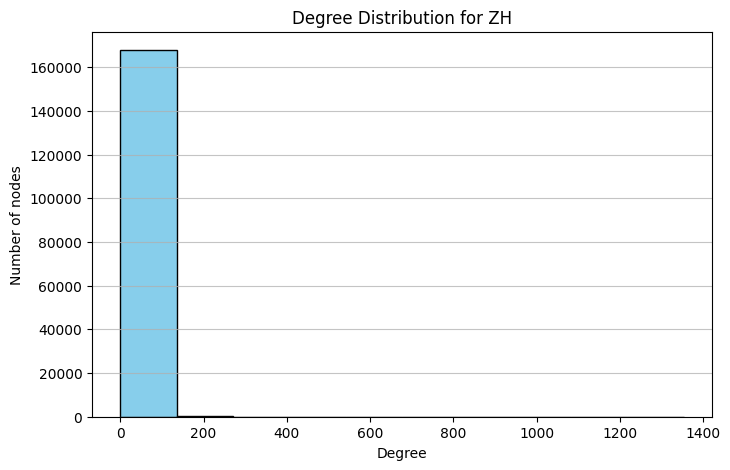

Remaining edges after filtering: 67532
DIFFERENCE 0


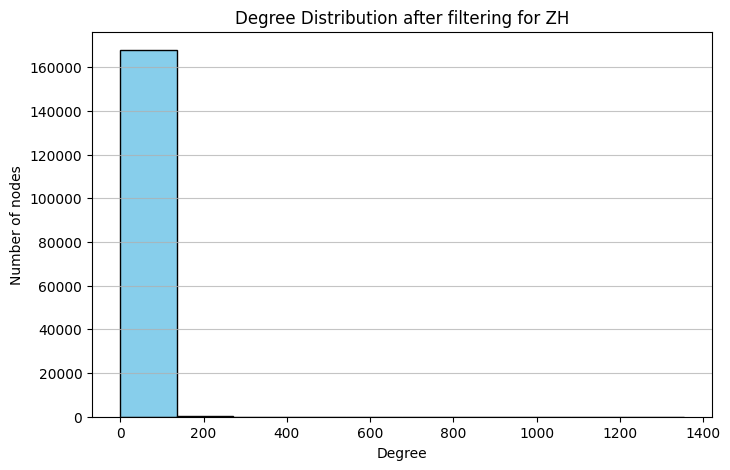


LANGUAGE: FR
Initial edges: 123529
Average degree: 1.4701632866799963


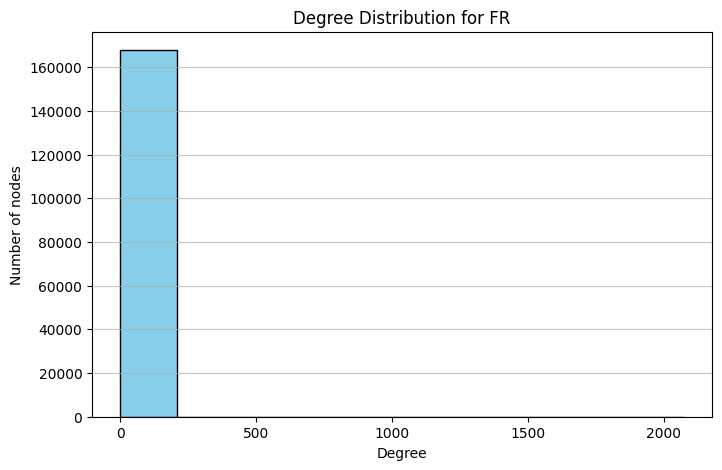

Remaining edges after filtering: 122698
DIFFERENCE 831


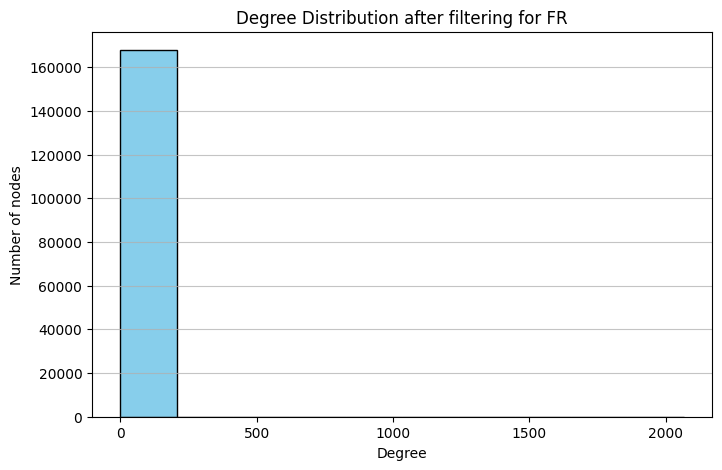


LANGUAGE: ES
Initial edges: 85984
Average degree: 1.0229796853157254


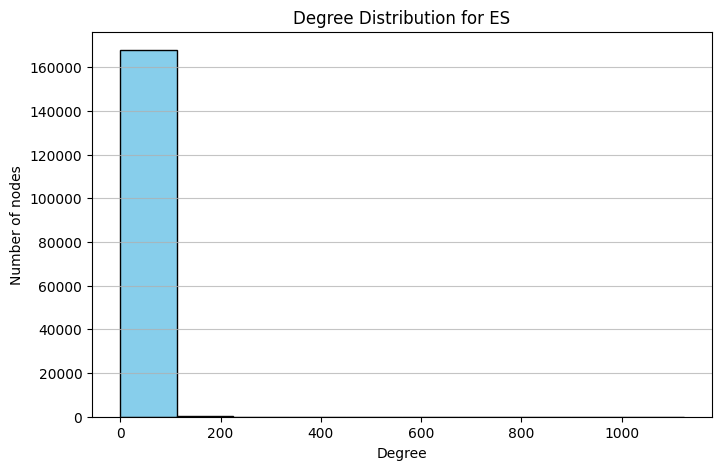

Remaining edges after filtering: 85285
DIFFERENCE 699


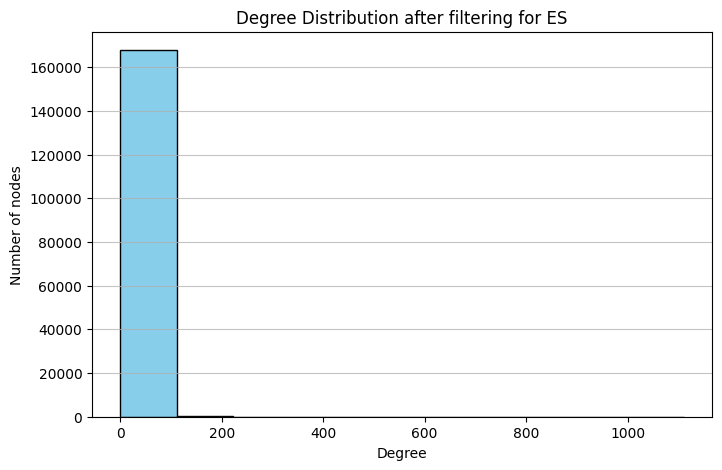


LANGUAGE: RU
Initial edges: 46696
Average degree: 0.5561961027204726


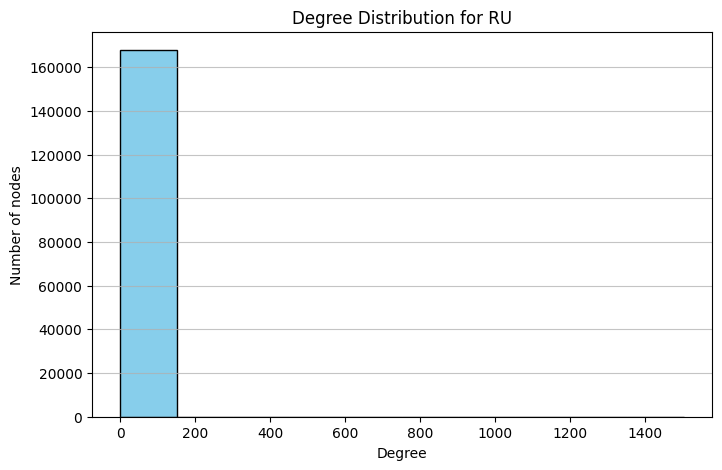

Remaining edges after filtering: 46696
DIFFERENCE 0


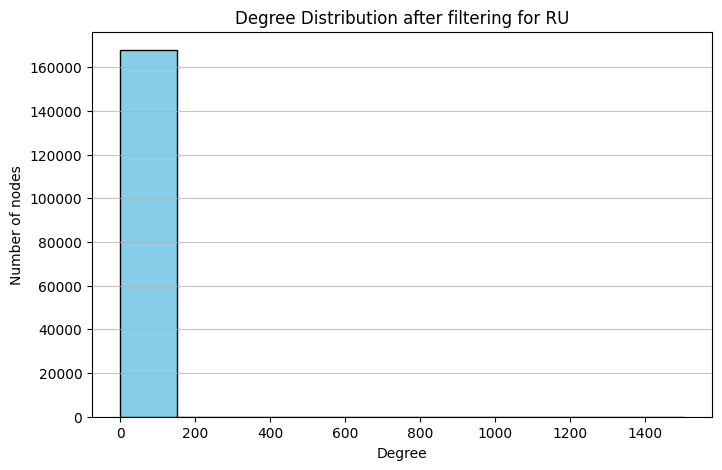

In [74]:
process_language_subgraphs(twitch_edges, chosen_lang=list(chosen_lang))


In [34]:
# Save both files
# twitch_edges.to_csv('twitch_edges.csv', sep='|', index=False)
# twitch_nodes.to_csv('twitch_features.csv', sep='|', index=False)

## Attempt to Prune


In [7]:
import pandas as pd

# Load edge list
twitch_edges = pd.read_csv('twitch_edges.csv', sep='|')

# Load node features
twitch_nodes = pd.read_csv('twitch_features.csv', sep='|')


In [36]:
display(twitch_edges.head(2))
display(twitch_nodes.head(2))

,numeric_id_1,numeric_id_2,created_at_1,created_at_2,updated_at_1,updated_at_2,life_time_1,life_time_2,views_1,views_2,dead_account_1,dead_account_2,language_1,language_2,affiliate_1,affiliate_2,mature_1,mature_2,color
0,27198,148201,2015-06-25,2013-07-04,2018-10-12,2018-10-06,1205,1920,7941991,730,0,0,FR,FR,0,0,0,1,black
1,27198,6662,2015-06-25,2013-04-07,2018-10-12,2018-10-08,1205,2010,7941991,2774,0,0,FR,FR,0,1,0,1,black


,views,mature,life_time,created_at,updated_at,numeric_id,dead_account,language,affiliate,color
0,775,1,577,2017-03-14,2018-10-12,7,0,FR,0,royalblue
1,2002,0,1910,2013-05-17,2018-08-09,14,0,RU,0,slategray


In [48]:
def remove_spoke_edges_from_hubs_only(
    twitch_nodes,
    twitch_edges,
    removal_fraction=0.1,
    views_percentile=80,
    degree_percentile=80,
    seed=None,
    verbose=True,
):
    import numpy as np
    import igraph as ig

    np.random.seed(seed)

    nodes_idxed = twitch_nodes.set_index("numeric_id")
    nodes_idxed.index = nodes_idxed.index.astype(int)

    edges = list(
        twitch_edges[["numeric_id_1", "numeric_id_2"]].itertuples(index=False, name=None)
    )
    g = ig.Graph.TupleList(edges, directed=False, vertex_name_attr="name")
    g.vs["name"] = [int(n) for n in g.vs["name"]]

    g.vs["views"] = [
        nodes_idxed.at[n, "views"] if n in nodes_idxed.index else 0 for n in g.vs["name"]
    ]
    g.vs["language"] = [
        nodes_idxed.at[n, "language"] if n in nodes_idxed.index else None for n in g.vs["name"]
    ]
    g.vs["degree"] = g.degree()

    views = np.array([v if v is not None else 0 for v in g.vs["views"]])
    degrees = np.array(g.vs["degree"])

    views_threshold = np.percentile(views, views_percentile)
    degree_threshold = np.percentile(degrees, degree_percentile)

    protected_nodes = set(
        v["name"]
        for v in g.vs
        if (v["views"] is not None and v["views"] >= views_threshold)
        or (v["degree"] is not None and v["degree"] >= degree_threshold)
    )

    edges_connected_to_hubs = []
    edges_other = []

    for e in g.es:
        src = g.vs[e.source]
        tgt = g.vs[e.target]

        src_is_protected = src["name"] in protected_nodes
        tgt_is_protected = tgt["name"] in protected_nodes

        # Identify edges between hub <-> spoke (exactly one protected node)
        if src_is_protected != tgt_is_protected:
            edges_connected_to_hubs.append(e.index)
        else:
            # All other edges (hub-hub or spoke-spoke), keep by default
            edges_other.append(e.index)

    n_to_remove = int(removal_fraction * len(edges_connected_to_hubs))
    if n_to_remove > 0 and len(edges_connected_to_hubs) >= n_to_remove:
        edges_to_remove = set(
            np.random.choice(edges_connected_to_hubs, size=n_to_remove, replace=False)
        )
    else:
        edges_to_remove = set()

    # Keep all edges except those randomly removed from hub spokes
    edges_to_keep = set(edges_other).union(set(edges_connected_to_hubs) - edges_to_remove)

    cleaned_edges = twitch_edges.iloc[list(edges_to_keep)].reset_index(drop=True)

    nodes_in_edges = set(cleaned_edges["numeric_id_1"]).union(set(cleaned_edges["numeric_id_2"]))
    cleaned_nodes = nodes_idxed.loc[nodes_idxed.index.isin(nodes_in_edges)].reset_index()

    if verbose:
        print(f"Original edges: {len(twitch_edges)}")
        print(f"Edges connected to hubs: {len(edges_connected_to_hubs)}")
        print(f"Edges removed (hub spokes): {len(edges_to_remove)}")
        print(f"Edges remaining: {len(cleaned_edges)}")

    return cleaned_nodes, cleaned_edges

In [51]:
all_cleaned_nodes = []
all_cleaned_edges = []

for lang in chosen_lang:
    # Filter edges where language_1 equals the current language
    df_lang = twitch_edges[twitch_edges['language_1'] == lang]
    print(f"LANGUAGE {lang}: {len(df_lang)} edges before filtering")
    
    # Run pruning on the filtered edges subset
    cleaned_nodes, cleaned_edges = remove_spoke_edges_from_hubs_only(
        twitch_nodes,
        df_lang,
        removal_fraction=0.2,
        seed=42,
        verbose=False,  # suppress internal print if you want cleaner output here
    )
    
    print(f"{lang}: {len(cleaned_edges)} edges after filtering")

    all_cleaned_nodes.append(cleaned_nodes)
    all_cleaned_edges.append(cleaned_edges)

# Combine all cleaned nodes and edges from all languages
final_nodes = pd.concat(all_cleaned_nodes).drop_duplicates(subset='numeric_id').reset_index(drop=True)
final_edges = pd.concat(all_cleaned_edges).reset_index(drop=True)

print(f"Total nodes after filtering: {len(final_nodes)}")
print(f"Total edges after filtering: {len(final_edges)}")

LANGUAGE ZH: 67532 edges before filtering
ZH: 61644 edges after filtering
LANGUAGE FR: 123529 edges before filtering
FR: 111921 edges after filtering
LANGUAGE ES: 85984 edges before filtering
ES: 78624 edges after filtering
LANGUAGE RU: 46696 edges before filtering
RU: 42636 edges after filtering
Total nodes after filtering: 19246
Total edges after filtering: 294825


## Awesome now lets find interconnected graph

In [1]:
import igraph as ig
import pandas as pd

# Assuming your DataFrames are named twitch_edges and nodes_df

def make_graph(twitch_edges):
    # Step 2: Create list of edge tuples (numeric_id_1, numeric_id_2)
    edges = list(twitch_edges[["numeric_id_1", "numeric_id_2"]].itertuples(index=False, name=None))

    # Step 3: Create graph from edges preserving the 'name' attribute (node id as string)
    g = ig.Graph.TupleList(edges, directed=False, vertex_name_attr="name")

    # Step 4: Convert vertex 'name' attribute to int (assumed numeric_id)
    g.vs["name"] = [int(n) for n in g.vs["name"]]

    # Step 5: Prepare node attribute mapping for fast lookup
    # Map node_id to index in nodes_df to avoid repeated filtering
    nodes_df_indexed = twitch_nodes.set_index("numeric_id")

    # List of attributes to add
    attributes = [
        "views", "mature", "life_time", "created_at", "updated_at",
        "dead_account", "language", "affiliate", "color"
    ]

    # Step 6: Add node attributes to graph vertices
    for attr in attributes:
        attr_values = []
        for node_id in g.vs["name"]:
            try:
                val = nodes_df_indexed.at[node_id, attr]
            except KeyError:
                val = None  # In case node_id not found in nodes_df
            attr_values.append(val)
        g.vs[attr] = attr_values

    return g



In [51]:
inter_edges = pd.read_csv('twitch_intercommunity.csv', sep='|')
# Load node features
twitch_nodes = pd.read_csv('twitch_features.csv', sep='|')
g = make_graph(inter_edges)

In [5]:
def graph_summary(g):
    # Diameter and average geodesic length (on largest connected component)
    components = g.clusters()
    largest_cc = components.giant()

    # Number of nodes
    n_nodes = g.vcount()
    
    # Density
    density = g.density()
    
    try:
        diameter = largest_cc.diameter(directed=False)
    except Exception:
        diameter = None
    try:
        avg_geo = largest_cc.average_path_length(directed=False)
    except Exception:
        avg_geo = None
    # Number of edges
    n_edges = g.ecount()
    # Count number of affiliated nodes (non-null, non-empty 'affiliate' attribute)
    if "affiliate" in g.vs.attributes():
        affiliates = [a for a in g.vs["affiliate"] if a not in (None, "", False)]
        n_affiliated = len(affiliates)
    else:
        n_affiliated = None

    # Calculate average view count
    if "views" in g.vs.attributes():
        views = [v for v in g.vs["views"] if v is not None]
        if len(views) > 0:
            avg_view = sum(views) / len(views)
        else:
            avg_view = None
    else:
        avg_view = None

    # Return results dictionary
    return {
        "num_nodes": n_nodes,
        "density": density,
        "diameter": diameter,
        "average_geodesic_length": avg_geo,
        "num_edges_total": n_edges,
        "num_affiliated_nodes": n_affiliated,
        "average_view_count": avg_view,
    }

summary = graph_summary(g)
print(summary)

{'num_nodes': 2623, 'density': 0.0008366404914804873, 'diameter': 16, 'average_geodesic_length': 6.271304284800903, 'num_edges_total': 2877, 'num_affiliated_nodes': 1033, 'average_view_count': 1775757.9767441861}


/var/folders/mv/b_rsh5351dgghy2nktxknr540000gn/T/ipykernel_61025/717619384.py:3: DeprecationWarning: Graph.clusters() is deprecated; use Graph.connected_components() instead
  components = g.clusters()


In [33]:
components = g.components()
num_components = len(components)

print("Number of connected components:", num_components)

print("Sizes of connected components:", components.sizes())

largest_cc = components.giant()
print("Largest connected component size:", largest_cc.vcount())

Number of connected components: 266
Sizes of connected components: [1966, 5, 2, 2, 5, 2, 2, 3, 2, 2, 2, 3, 3, 2, 2, 4, 2, 2, 16, 2, 2, 2, 2, 2, 3, 3, 2, 2, 2, 2, 2, 4, 3, 3, 2, 2, 2, 2, 3, 4, 2, 2, 2, 3, 6, 2, 2, 2, 3, 2, 3, 2, 3, 4, 2, 2, 2, 2, 2, 3, 2, 6, 2, 2, 2, 3, 2, 3, 2, 2, 2, 12, 2, 4, 2, 2, 2, 2, 2, 8, 2, 2, 4, 3, 2, 2, 7, 2, 2, 7, 2, 2, 2, 3, 2, 3, 2, 2, 2, 4, 3, 2, 3, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 4, 2, 2, 2, 2, 2, 2, 4, 4, 2, 2, 2, 2, 2, 3, 2, 3, 2, 2, 2, 2, 2, 5, 6, 3, 2, 4, 2, 2, 2, 3, 4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 3, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 3, 3, 2, 3, 2, 4, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Largest connected component size: 1966


In [6]:
from collections import defaultdict

def language_edge_affiliation_types(g):
    # Step 1: get largest connected component
    components = g.clusters()  # or g.components() if igraph >=0.9
    largest_cc = components.giant()
    langs = largest_cc.vs["language"]  # language per node
    affiliates = largest_cc.vs["affiliate"]  # affiliate attribute per node
    
    lang_pair_stats = defaultdict(lambda: {
        "edge_count": 0,
        "single_affiliated_edges": 0,
        "double_affiliated_edges": 0,
        "edges": []  # list to store actual edges (tuples of node names or IDs)
    })
    
    for edge in largest_cc.es:
        src = edge.source
        tgt = edge.target
        
        lang_src = langs[src]
        lang_tgt = langs[tgt]
        
        lang_pair = tuple(sorted([lang_src, lang_tgt]))
        lang_pair_stats[lang_pair]["edge_count"] += 1
        
        # Get node identifiers - can be name or index
        # Change 'name' below to whatever vertex attribute represents node names if needed
        src_name = largest_cc.vs[src]["name"] if "name" in largest_cc.vs.attributes() else src
        tgt_name = largest_cc.vs[tgt]["name"] if "name" in largest_cc.vs.attributes() else tgt
        
        # Store edge as a tuple of node ids or names
        lang_pair_stats[lang_pair]["edges"].append((src_name, tgt_name))
        
        # Evaluate affiliations (True = affiliated)
        aff_src = affiliates[src] not in (None, "", False)
        aff_tgt = affiliates[tgt] not in (None, "", False)
        
        if aff_src and aff_tgt:
            lang_pair_stats[lang_pair]["double_affiliated_edges"] += 1
        elif aff_src or aff_tgt:
            lang_pair_stats[lang_pair]["single_affiliated_edges"] += 1
        
    return dict(lang_pair_stats)

# Example usage:
lang_aff_stats = language_edge_affiliation_types(g)

# Print summary
for pair, stats in sorted(lang_aff_stats.items(), key=lambda x: x[1]["edge_count"], reverse=True):
    print(f"{pair}: total_edges={stats['edge_count']}, "
          f"single_affiliated={stats['single_affiliated_edges']}, "
          f"double_affiliated={stats['double_affiliated_edges']}, "
          f"edges_sample={stats['edges'][:5]}")  # print first 5 edges as sample

('ES', 'FR'): total_edges=683, single_affiliated=329, double_affiliated=79, edges_sample=[(27198, 51230), (27198, 138775), (27198, 141364), (102163, 256), (119716, 125804)]
('FR', 'RU'): total_edges=444, single_affiliated=206, double_affiliated=45, edges_sample=[(119716, 63864), (119716, 136249), (119716, 94488), (113545, 39469), (2941, 134556)]
('ES', 'ZH'): total_edges=375, single_affiliated=135, double_affiliated=8, edges_sample=[(121614, 135239), (127967, 49338), (46470, 143778), (130988, 132582), (87068, 71876)]
('ES', 'RU'): total_edges=372, single_affiliated=157, double_affiliated=30, edges_sample=[(127967, 74384), (127967, 87514), (74384, 130988), (130988, 92424), (104066, 4897)]
('FR', 'ZH'): total_edges=368, single_affiliated=185, double_affiliated=26, edges_sample=[(27198, 10748), (27198, 41463), (119716, 76970), (2941, 82692), (2941, 158314)]
('RU', 'ZH'): total_edges=243, single_affiliated=97, double_affiliated=6, edges_sample=[(103258, 150771), (92424, 71630), (92424, 125

/var/folders/mv/b_rsh5351dgghy2nktxknr540000gn/T/ipykernel_61025/1106320482.py:5: DeprecationWarning: Graph.clusters() is deprecated; use Graph.connected_components() instead
  components = g.clusters()  # or g.components() if igraph >=0.9


### Interdependency analysis

1. Look at interconnected communities and see how connections impact views to measure intercommunity influence

* Spanish and French
* French and Russian
* Spanish and Chinese
* Spanish and Russian
* French and Chinese
* Russian and Chinese

2. Measure the difference in affiliation percentage and viewership count as edges are removed
Access edges for a specific language pair, for example ('English', 'French')
edges_en_fr = lang_aff_stats.get(('English', 'French'), {}).get('edges', [])

3. Graph for each community
Remove the highest betweeness edges from the community graph and look at metrics again

In [11]:
# Get spanish df and graph
spanish_df = twitch_edges[twitch_edges['language_1'] == 'ES']
spanish_g = make_graph(spanish_df)
print(graph_summary(spanish_g))

# Get french df and graph
french_df = twitch_edges[twitch_edges['language_1'] == 'FR']
french_g = make_graph(french_df)
print(graph_summary(french_g))

# Get russian df and graph
russian_df = twitch_edges[twitch_edges['language_1'] == 'RU']
russian_g = make_graph(russian_df)
print(graph_summary(russian_g))

# Get russian df and graph
chinese_df = twitch_edges[twitch_edges['language_1'] == 'ZH']
chinese_g = make_graph(chinese_df)
print(graph_summary(chinese_g))

/var/folders/mv/b_rsh5351dgghy2nktxknr540000gn/T/ipykernel_61025/717619384.py:3: DeprecationWarning: Graph.clusters() is deprecated; use Graph.connected_components() instead
  components = g.clusters()


{'num_nodes': 5965, 'density': 0.004833921101349645, 'diameter': 8, 'average_geodesic_length': 2.9674438255565265, 'num_edges_total': 85984, 'num_affiliated_nodes': 3070, 'average_view_count': 422142.2746018441}


/var/folders/mv/b_rsh5351dgghy2nktxknr540000gn/T/ipykernel_61025/717619384.py:3: DeprecationWarning: Graph.clusters() is deprecated; use Graph.connected_components() instead
  components = g.clusters()


{'num_nodes': 7355, 'density': 0.00456764790112236, 'diameter': 7, 'average_geodesic_length': 2.792416497963997, 'num_edges_total': 123529, 'num_affiliated_nodes': 3758, 'average_view_count': 400848.431407206}


/var/folders/mv/b_rsh5351dgghy2nktxknr540000gn/T/ipykernel_61025/717619384.py:3: DeprecationWarning: Graph.clusters() is deprecated; use Graph.connected_components() instead
  components = g.clusters()


{'num_nodes': 5071, 'density': 0.003632520769180205, 'diameter': 8, 'average_geodesic_length': 2.9995076624507604, 'num_edges_total': 46696, 'num_affiliated_nodes': 2273, 'average_view_count': 572120.8045750345}


/var/folders/mv/b_rsh5351dgghy2nktxknr540000gn/T/ipykernel_61025/717619384.py:3: DeprecationWarning: Graph.clusters() is deprecated; use Graph.connected_components() instead
  components = g.clusters()


{'num_nodes': 3209, 'density': 0.013120051227493747, 'diameter': 6, 'average_geodesic_length': 2.5882828071668444, 'num_edges_total': 67532, 'num_affiliated_nodes': 1147, 'average_view_count': 839189.5179183546}


In [71]:
import igraph as ig
import random
import matplotlib.pyplot as plt

def iterative_edge_node_removal_with_metrics(graph: ig.Graph,
                                            edges_dict: dict,
                                            frac_remove=0.1,
                                            max_iterations=10):
    """
    Iteratively removes a fraction of edges randomly from a given edges dictionary,
    removes isolated nodes, and tracks several metrics per iteration including:
    - number of nodes
    - number of edges
    - percentage of nodes with affiliate=True attribute
    - average 'views' attribute over all nodes
    - size of the giant (largest) connected component
    
    Args:
        graph (igraph.Graph): The igraph graph object; it will be modified in-place.
        edges_dict (dict): Dictionary with edges as keys (tuples of vertex ids).
        frac_remove (float): The fraction of edges to remove per iteration (default 0.1).
        max_iterations (int): Maximum number of iterations (default 5).
    """

    graph = graph.copy()
    candidate_edges = edges_dict
    total_to_remove = int(1 * len(candidate_edges))  # stop after removing 50%

    removed_edges = set()

    metrics = {
        "iteration": [],
        "num_edges": [],
        "num_nodes": [],
        "percent_affiliate": [],
        "avg_views": [],
        "num_components": [],
    }

    for itr in range(1, max_iterations + 1):
        remaining_edges = [e for e in candidate_edges if e not in removed_edges]
        if len(remaining_edges) == 0:
            print(f"Iteration {itr}: No edges left to remove, stopping.")
            break

        num_to_remove = max(1, int(frac_remove * len(remaining_edges)))
        edges_to_remove = remaining_edges[:num_to_remove]   # take first 'num_to_remove' edges in order
        removed_edges.update(edges_to_remove)

        # Remove edges from graph
        eids_to_remove = []
        for u, v in edges_to_remove:
            try:
                # If u/v are vertex names and graph has 'name' attribute:
                u_id = graph.vs.find(name=u).index
                v_id = graph.vs.find(name=v).index
                eid = graph.get_eid(u_id, v_id, directed=False, error=False)
                if eid != -1:
                    eids_to_remove.append(eid)
            except ValueError:
            # vertex name u or v not found
                continue
        graph.delete_edges(eids_to_remove)

        # Remove isolated nodes (degree == 0)
        isolated_nodes = [v.index for v in graph.vs if graph.degree(v.index) == 0]
        if isolated_nodes:
            graph.delete_vertices(isolated_nodes)

        # Compute metrics
        num_nodes = graph.vcount()
        num_edges = graph.ecount()

        affiliates = graph.vs.select(affiliate_eq=True) if 'affiliate' in graph.vertex_attributes() else []
        pct_affiliate = 100 * len(affiliates) / num_nodes if num_nodes > 0 else 0

        views_vals = [v['views'] for v in graph.vs if 'views' in graph.vertex_attributes() and v['views'] is not None]
        avg_views = sum(views_vals) / len(views_vals) if views_vals else 0

        components = graph.components()
        giant_size = len(components)

        # Store metrics
        metrics["iteration"].append(itr)
        metrics["num_edges"].append(num_edges)
        metrics["num_nodes"].append(num_nodes)
        metrics["percent_affiliate"].append(pct_affiliate)
        metrics["avg_views"].append(avg_views)
        metrics["num_components"].append(giant_size)

        print(f"Iteration {itr}: Removed {num_to_remove} edges; Remaining in dict: {len(remaining_edges) - num_to_remove}")
        print(f"  Nodes: {num_nodes}, Edges: {num_edges}, % Affiliate: {pct_affiliate:.2f}, Avg Views: {avg_views:.2f}, Giant Comp. Size: {giant_size}")

        if len(removed_edges) >= total_to_remove:
            print(f"Stopped after {itr} iterations (removed 50% of edges).")
            break

    return metrics 
    

In [13]:
# get the sets of edges

edges_es_fr = lang_aff_stats.get(('ES', 'FR'), {}).get('edges', [])
edges_es_zh = lang_aff_stats.get(('ES', 'ZH'), {}).get('edges', [])
edges_es_ru = lang_aff_stats.get(('ES', 'RU'), {}).get('edges', [])
edges_fr_zh = lang_aff_stats.get(('FR', 'ZH'), {}).get('edges', [])
edges_ru_zh = lang_aff_stats.get(('RU', 'ZH'), {}).get('edges', [])


In [36]:
import matplotlib.pyplot as plt
import itertools

def plot_metrics_per_type(all_metrics_dict):
    """
    Plots separate graphs for each metric.
    On each graph, all languages are shown together with different colors.
    
    Args:
        all_metrics_dict (dict):
            Keys: language/experiment labels (e.g. 'ES-ZH')
            Values: dict of lists of metrics, keys:
                - iteration
                - percent_affiliate
                - avg_views
                - giant_component_size
    """
    metrics_names = ['percent_affiliate', 'avg_views', 'num_components']
    metric_display_names = {
        'percent_affiliate': 'Affiliate Nodes %',
        'avg_views': 'Average Views',
        'num_components': 'Number of Component'
    }
    colors = plt.cm.get_cmap('tab10').colors

    for metric in metrics_names:
        plt.figure(figsize=(10, 5))
        for i, (lang_label, metrics) in enumerate(all_metrics_dict.items()):
            plt.plot(
                metrics['iteration'],
                metrics[metric],
                label=lang_label,
                color=colors[i % len(colors)],
                marker='o'
            )
        plt.title(f"{metric_display_names[metric]} over Iterations")
        plt.xlabel("Iteration")
        plt.ylabel(metric_display_names[metric])
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

Iteration 1: Removed 68 edges; Remaining in dict: 615
  Nodes: 5805, Edges: 85730, % Affiliate: 51.77, Avg Views: 383818.51, Giant Comp. Size: 7
Iteration 2: Removed 61 edges; Remaining in dict: 554
  Nodes: 5796, Edges: 85717, % Affiliate: 51.76, Avg Views: 384219.62, Giant Comp. Size: 7
Iteration 3: Removed 55 edges; Remaining in dict: 499
  Nodes: 5787, Edges: 85704, % Affiliate: 51.79, Avg Views: 373263.78, Giant Comp. Size: 7
Iteration 4: Removed 49 edges; Remaining in dict: 450
  Nodes: 5783, Edges: 85694, % Affiliate: 51.81, Avg Views: 371526.80, Giant Comp. Size: 7
Iteration 5: Removed 45 edges; Remaining in dict: 405
  Nodes: 5780, Edges: 85686, % Affiliate: 51.80, Avg Views: 364311.78, Giant Comp. Size: 7
Iteration 1: Removed 37 edges; Remaining in dict: 338
  Nodes: 5811, Edges: 85740, % Affiliate: 51.76, Avg Views: 381056.96, Giant Comp. Size: 7
Iteration 2: Removed 33 edges; Remaining in dict: 305
  Nodes: 5803, Edges: 85728, % Affiliate: 51.78, Avg Views: 377546.46, Giant

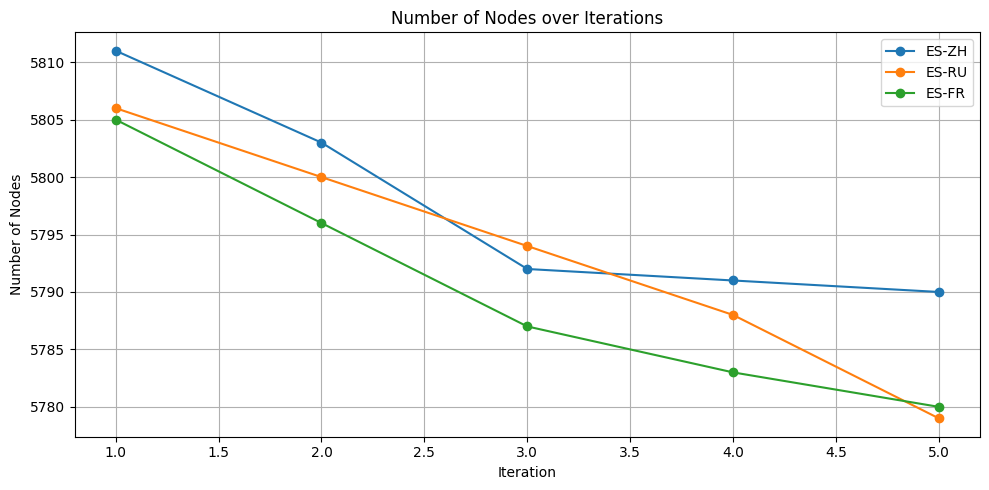

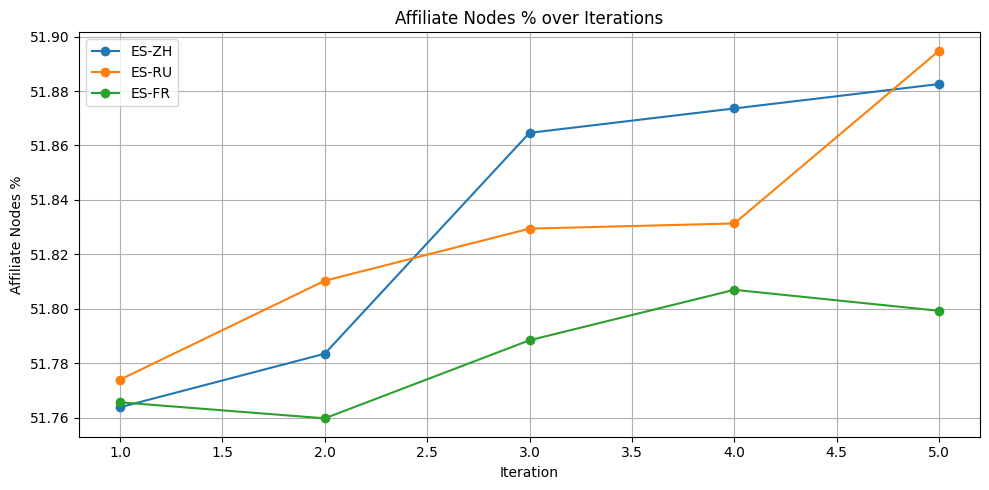

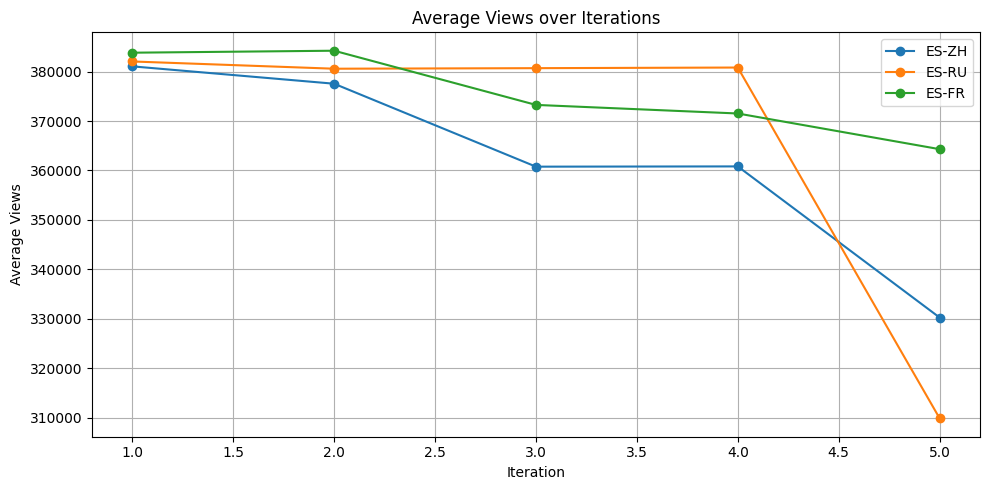

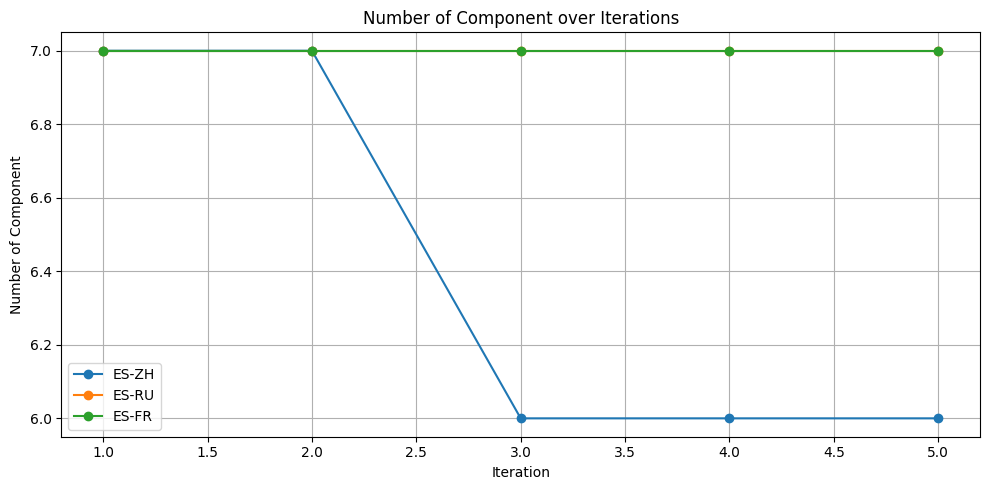

In [34]:
# edges_dict: spanish and french
es_fr_metrics = iterative_edge_node_removal_with_metrics(spanish_g, edges_es_fr)
# edges_dict: spanish and chinese
es_zh_metrics = iterative_edge_node_removal_with_metrics(spanish_g, edges_es_zh)
# edges_dict: spanish and russian
es_ru_metrics = iterative_edge_node_removal_with_metrics(spanish_g, edges_es_ru)

spanish_metrics = {
    'ES-ZH': es_zh_metrics,
    'ES-RU': es_ru_metrics,
    'ES-FR': es_fr_metrics
}

plot_metrics_per_type(spanish_metrics)

Iteration 1: Removed 68 edges; Remaining in dict: 615
  Nodes: 7334, Edges: 123491, % Affiliate: 51.10, Avg Views: 398857.81, Giant Comp. Size: 3
Iteration 2: Removed 61 edges; Remaining in dict: 554
  Nodes: 7316, Edges: 123457, % Affiliate: 51.09, Avg Views: 398614.68, Giant Comp. Size: 3
Iteration 3: Removed 55 edges; Remaining in dict: 499
  Nodes: 7291, Edges: 123421, % Affiliate: 51.15, Avg Views: 389549.38, Giant Comp. Size: 3
Iteration 4: Removed 49 edges; Remaining in dict: 450
  Nodes: 7269, Edges: 123390, % Affiliate: 51.15, Avg Views: 387625.55, Giant Comp. Size: 3
Iteration 5: Removed 45 edges; Remaining in dict: 405
  Nodes: 7249, Edges: 123362, % Affiliate: 51.14, Avg Views: 388439.10, Giant Comp. Size: 3
Iteration 1: Removed 36 edges; Remaining in dict: 332
  Nodes: 7348, Edges: 123511, % Affiliate: 51.13, Avg Views: 400777.22, Giant Comp. Size: 3
Iteration 2: Removed 33 edges; Remaining in dict: 299
  Nodes: 7336, Edges: 123495, % Affiliate: 51.19, Avg Views: 395890.95

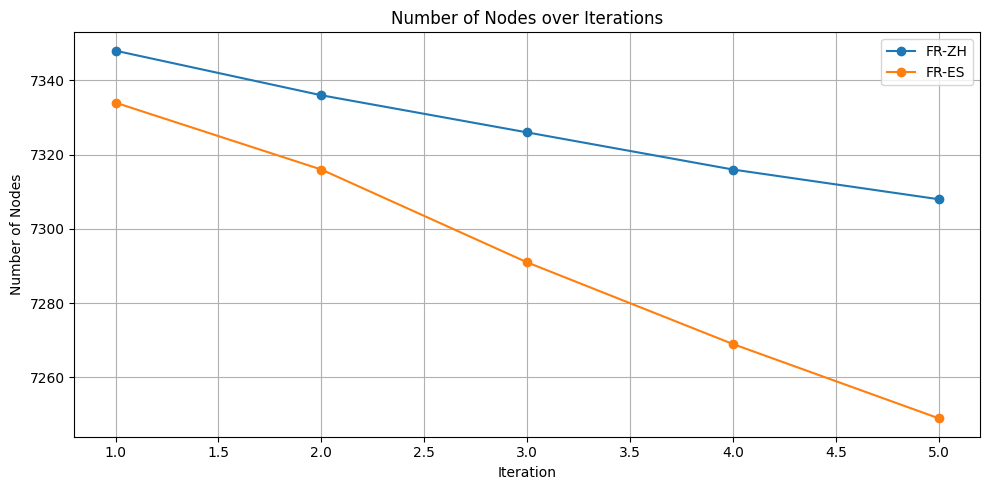

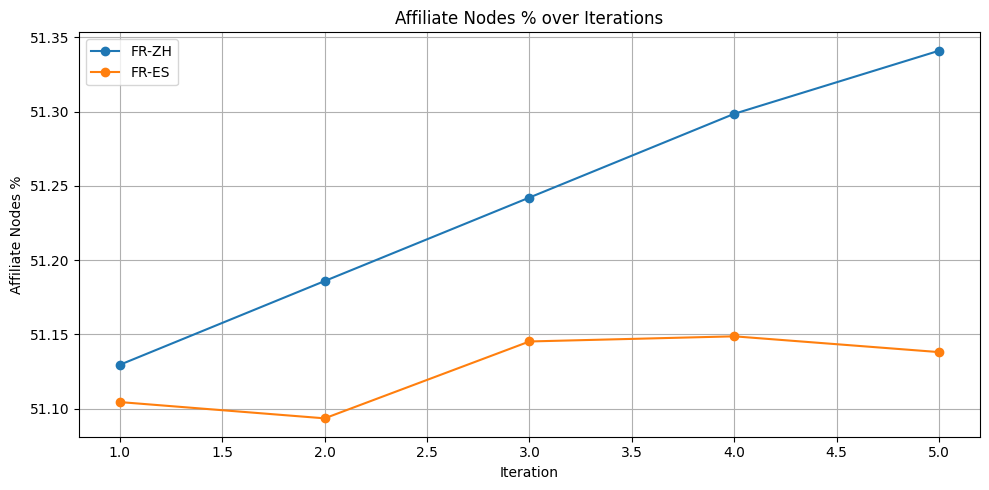

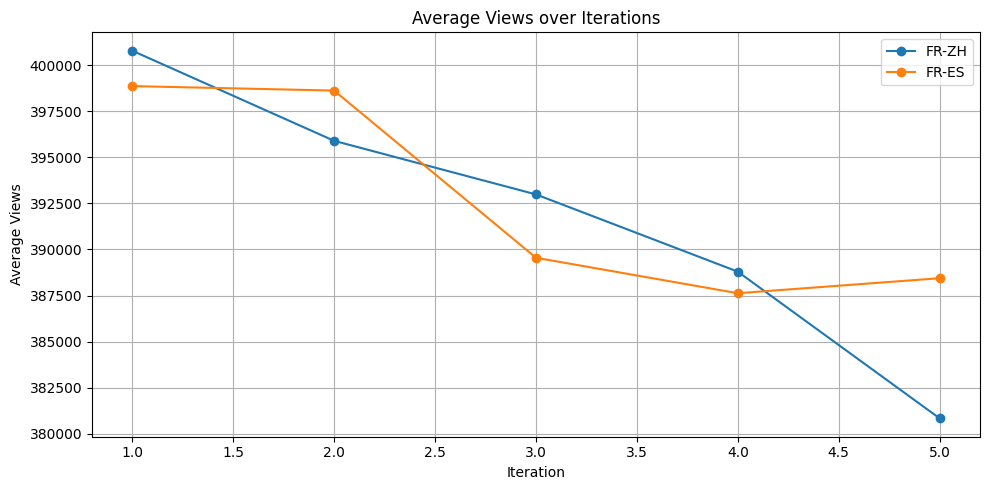

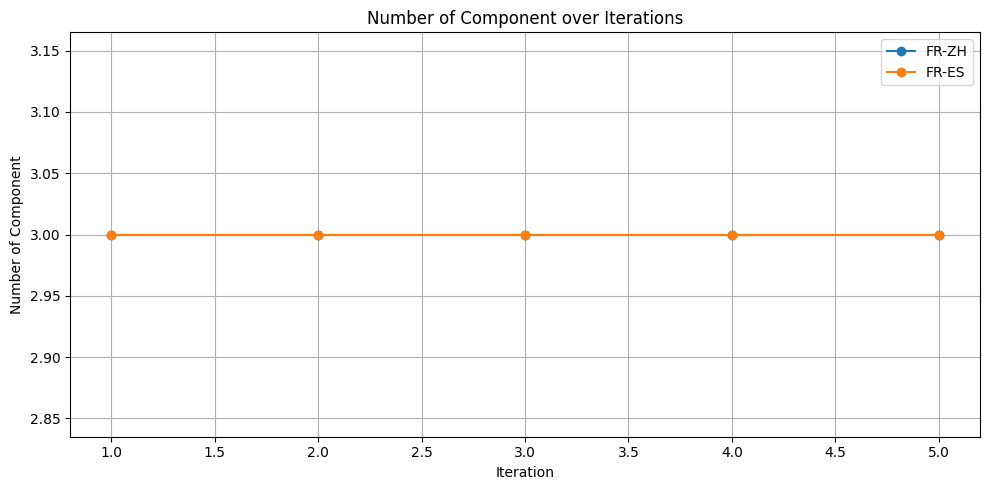

In [35]:
# edges_dict: french and spanish
fr_es_metrics = iterative_edge_node_removal_with_metrics(french_g, edges_es_fr)
# edges_dict: french and chinese
fr_zh_metrics = iterative_edge_node_removal_with_metrics(french_g, edges_fr_zh)

french_metrics = {
    'FR-ZH': fr_zh_metrics,
    'FR-ES': fr_es_metrics
}

plot_metrics_per_type(french_metrics)

Iteration 1: Removed 37 edges; Remaining in dict: 338
  Nodes: 3194, Edges: 67506, % Affiliate: 35.79, Avg Views: 842579.27, Giant Comp. Size: 4
Iteration 2: Removed 33 edges; Remaining in dict: 305
  Nodes: 3180, Edges: 67486, % Affiliate: 35.72, Avg Views: 845817.95, Giant Comp. Size: 4
Iteration 3: Removed 30 edges; Remaining in dict: 275
  Nodes: 3165, Edges: 67462, % Affiliate: 35.73, Avg Views: 849679.61, Giant Comp. Size: 4
Iteration 4: Removed 27 edges; Remaining in dict: 248
  Nodes: 3154, Edges: 67448, % Affiliate: 35.76, Avg Views: 848881.06, Giant Comp. Size: 4
Iteration 5: Removed 24 edges; Remaining in dict: 224
  Nodes: 3144, Edges: 67432, % Affiliate: 35.72, Avg Views: 851513.62, Giant Comp. Size: 4
Iteration 1: Removed 36 edges; Remaining in dict: 332
  Nodes: 3203, Edges: 67519, % Affiliate: 35.78, Avg Views: 840698.82, Giant Comp. Size: 4
Iteration 2: Removed 33 edges; Remaining in dict: 299
  Nodes: 3192, Edges: 67502, % Affiliate: 35.71, Avg Views: 843456.73, Giant

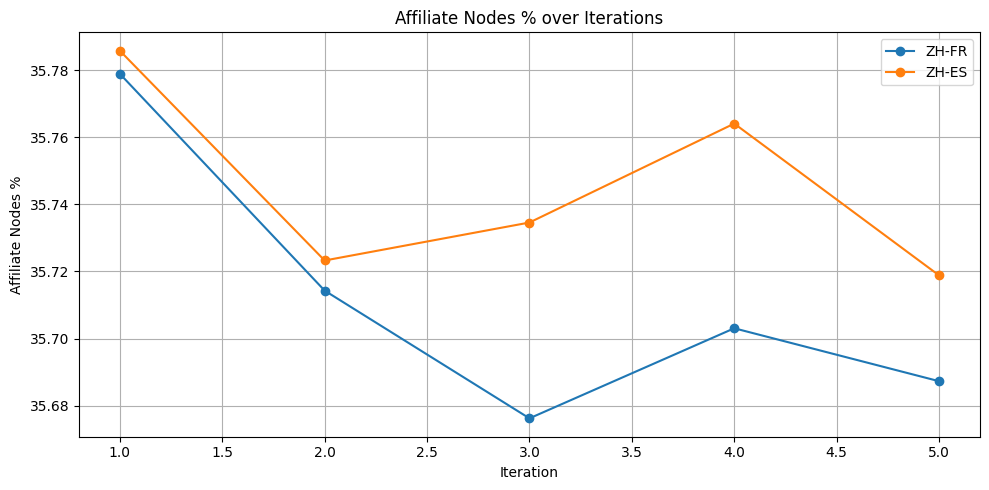

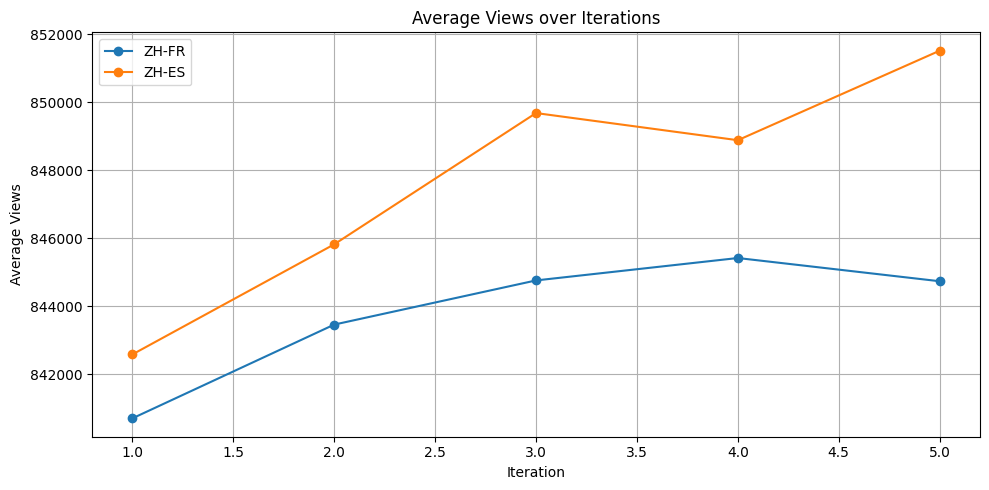

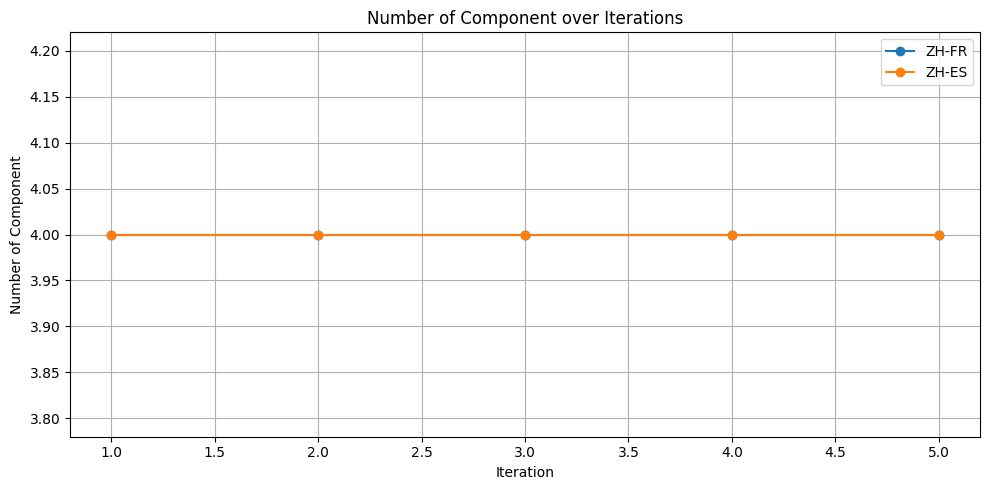

In [37]:
# edges_dict: french and spanish
zh_es_metrics = iterative_edge_node_removal_with_metrics(chinese_g, edges_es_zh)
# edges_dict: french and chinese
zh_fr_metrics = iterative_edge_node_removal_with_metrics(chinese_g, edges_fr_zh)

chinese_metrics = {
    'ZH-FR': zh_fr_metrics,
    'ZH-ES': zh_es_metrics
}

plot_metrics_per_type(chinese_metrics)

In [72]:
entire_g = make_graph(twitch_edges)

edge_betweenness = g.edge_betweenness()

# Pair edges with their betweenness
edges_with_bet = list(zip(g.es, edge_betweenness))

# Sort edges descending by betweenness
edges_sorted = sorted(edges_with_bet, key=lambda x: x[1], reverse=True)

top_1000 = [(g.vs[edge.tuple[0]]['name'], g.vs[edge.tuple[1]]['name']) for edge, _ in edges_sorted]

print(len(top_1000))
print(top_1000[:5])

2877
[(85649, 96086), (92424, 54959), (41463, 96086), (54959, 45967), (92424, 71630)]


In [76]:
# 1. Group nodes by language
language_to_nodes = defaultdict(list)
for v in entire_g.vs:
    lang = v['language']
    language_to_nodes[lang].append(v.index)

# 2. Create subgraphs for each language community
language_communities = {}
for lang, nodes in language_to_nodes.items():
    subgraph = entire_g.subgraph(nodes)
    language_communities[lang] = subgraph
    print(f"Language '{lang}' community: {len(nodes)} nodes, {subgraph.ecount()} edges")

# 3. Create lists of all subgraphs
community_list = language_communities.values()

Language 'FR' community: 6604 nodes, 122503 edges
Language 'ES' community: 5463 nodes, 85316 edges
Language 'ZH' community: 2718 nodes, 66892 edges
Language 'RU' community: 4618 nodes, 46153 edges


In [74]:
top_1000_edges = top_1000

fr_g = language_communities.get('FR')
es_g = language_communities.get('ES')
ru_g = language_communities.get('RU')
zh_g = language_communities.get('ZH')


In [80]:
fr_metrics = iterative_edge_node_removal_with_metrics(french_g, top_1000_edges)
es_metrics = iterative_edge_node_removal_with_metrics(spanish_g, top_1000_edges)
ru_metrics = iterative_edge_node_removal_with_metrics(russian_g, top_1000_edges)
zh_metrics = iterative_edge_node_removal_with_metrics(chinese_g, top_1000_edges)

Iteration 1: Removed 575 edges; Remaining in dict: 2302
  Nodes: 7282, Edges: 123332, % Affiliate: 51.39, Avg Views: 321437.30, Giant Comp. Size: 4
Iteration 2: Removed 460 edges; Remaining in dict: 1842
  Nodes: 7196, Edges: 123185, % Affiliate: 51.72, Avg Views: 288648.89, Giant Comp. Size: 3
Iteration 3: Removed 368 edges; Remaining in dict: 1474
  Nodes: 7058, Edges: 123022, % Affiliate: 52.00, Avg Views: 216163.06, Giant Comp. Size: 3
Iteration 4: Removed 294 edges; Remaining in dict: 1180
  Nodes: 6980, Edges: 122922, % Affiliate: 52.16, Avg Views: 205594.54, Giant Comp. Size: 3
Iteration 5: Removed 236 edges; Remaining in dict: 944
  Nodes: 6897, Edges: 122835, % Affiliate: 52.24, Avg Views: 205938.57, Giant Comp. Size: 3
Iteration 1: Removed 575 edges; Remaining in dict: 2302
  Nodes: 5770, Edges: 85667, % Affiliate: 52.03, Avg Views: 268908.52, Giant Comp. Size: 7
Iteration 2: Removed 460 edges; Remaining in dict: 1842
  Nodes: 5724, Edges: 85606, % Affiliate: 52.18, Avg Views

In [81]:
import matplotlib.pyplot as plt

def plot_metrics_for_single_country(metrics, country_label=None):
    """
    Plots separate subplots for each metric of a single country/language.
    
    Args:
        metrics (dict): Keys are metric names and values are lists per iteration, including:
                        - 'iteration'
                        - 'percent_affiliate'
                        - 'avg_views'
                        - 'num_components'
        country_label (str): Optional label to display as the figure title
    """
    metrics_names = ['percent_affiliate', 'avg_views', 'num_components']
    metric_display_names = {
        'percent_affiliate': 'Affiliate Nodes %',
        'avg_views': 'Average Views',
        'num_components': 'Number of Components'
    }
    
    fig, axs = plt.subplots(len(metrics_names), 1, figsize=(10, 4 * len(metrics_names)), sharex=True)
    
    for i, metric in enumerate(metrics_names):
        axs[i].plot(metrics['iteration'], metrics[metric], marker='o', color='tab:blue')
        axs[i].set_ylabel(metric_display_names[metric])
        axs[i].grid(True)

    axs[-1].set_xlabel('Iteration')
    
    if country_label:
        fig.suptitle(f"Metrics Over Iterations for {country_label}", fontsize=16)
    
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle
    plt.show()

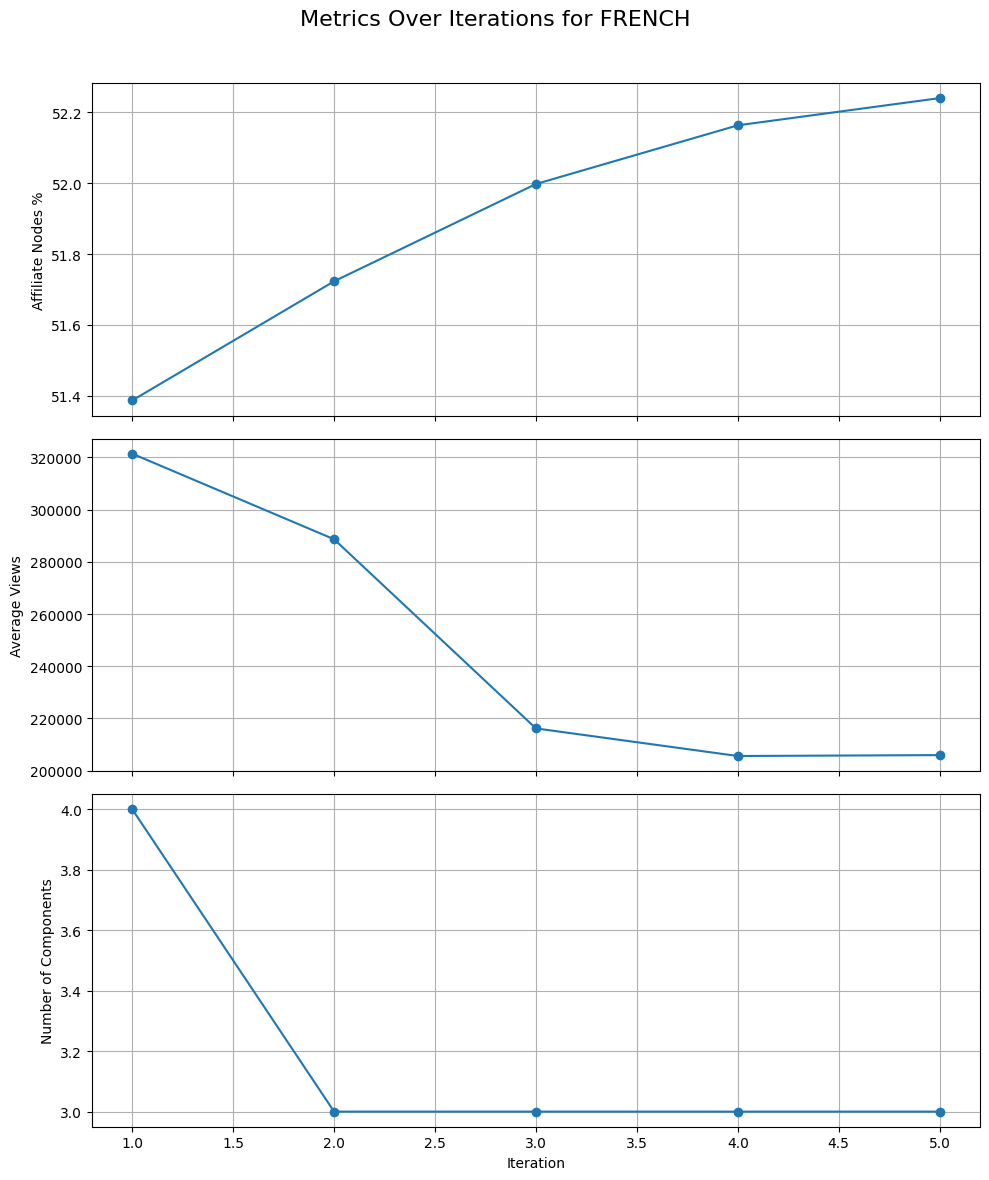

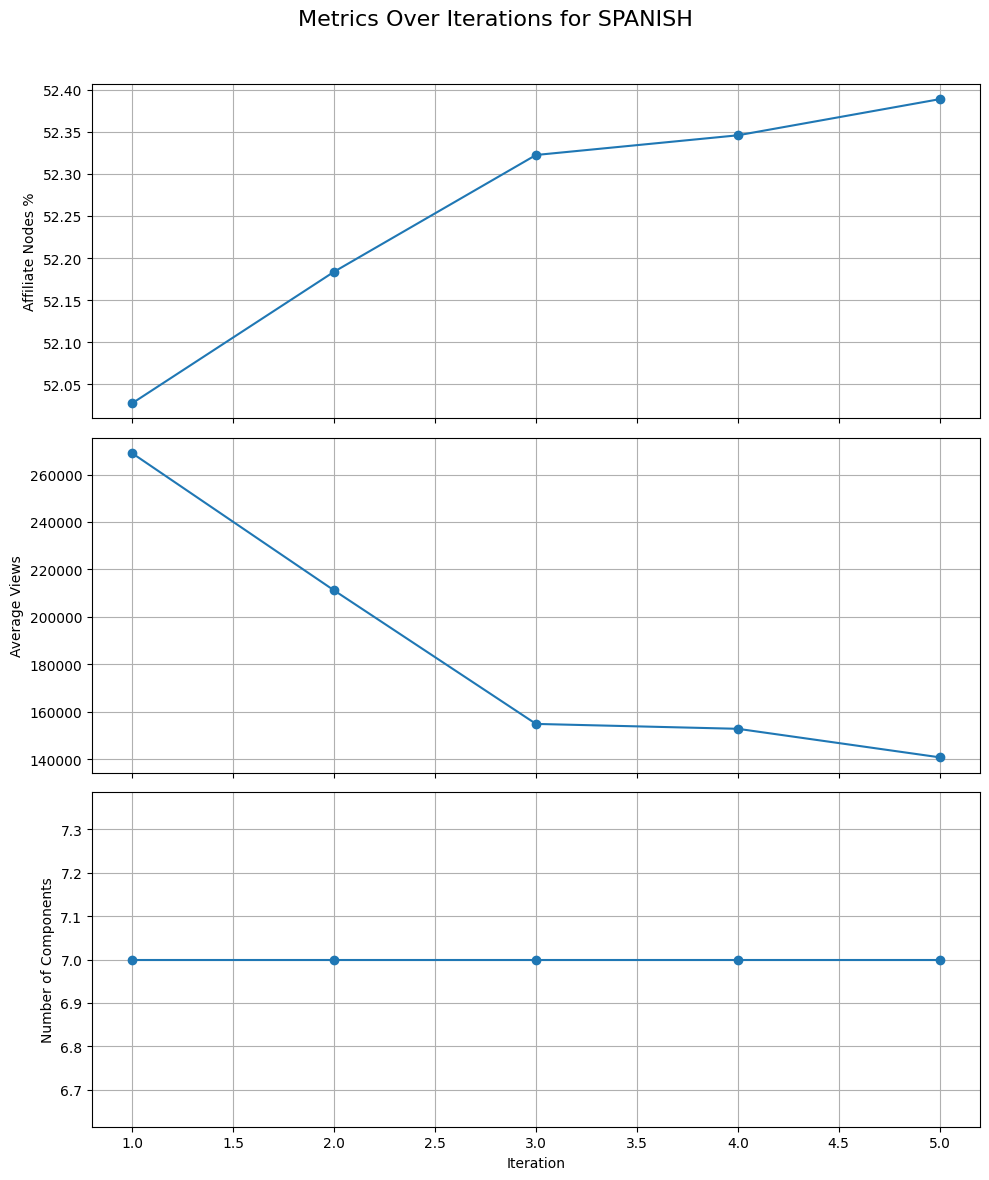

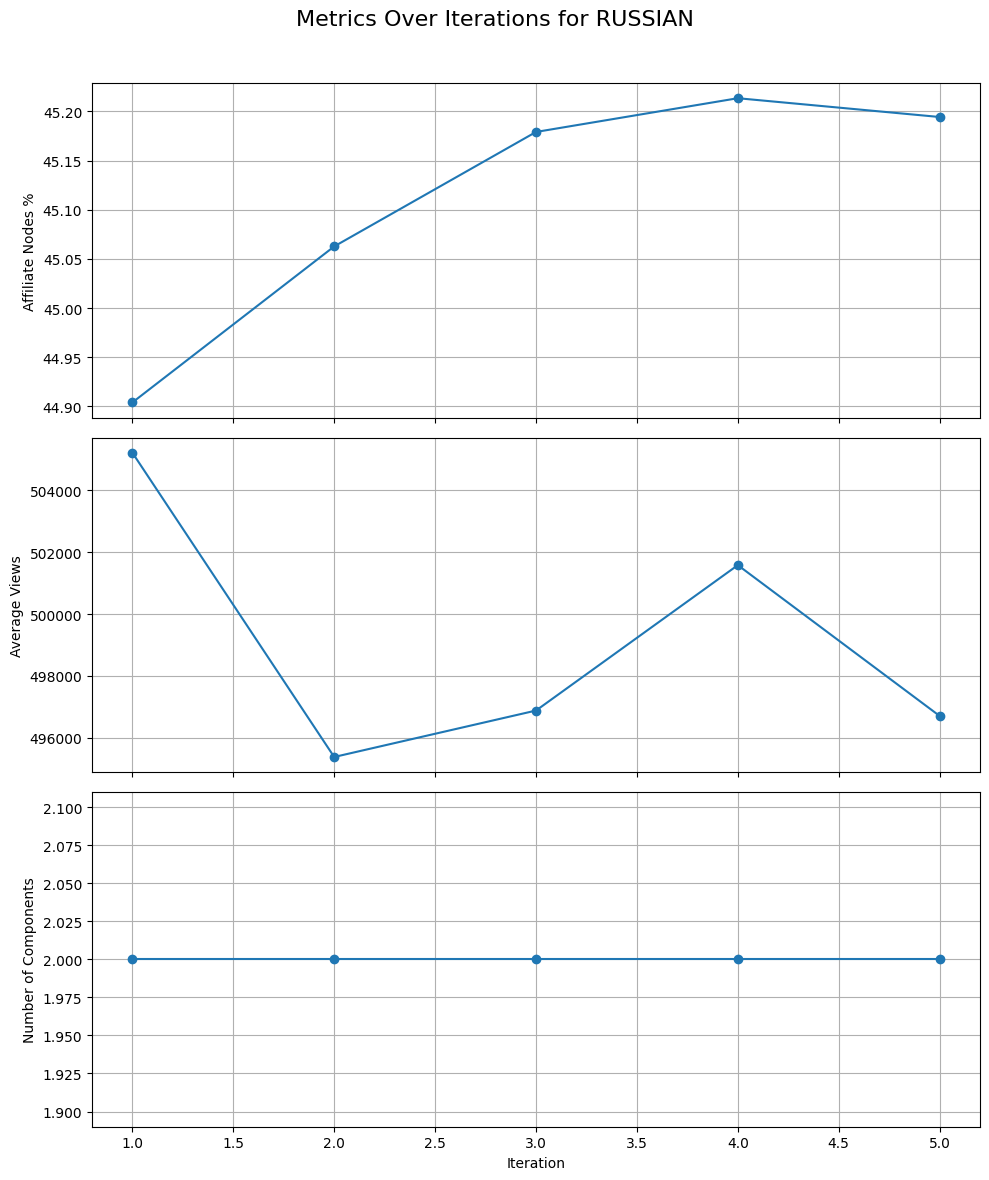

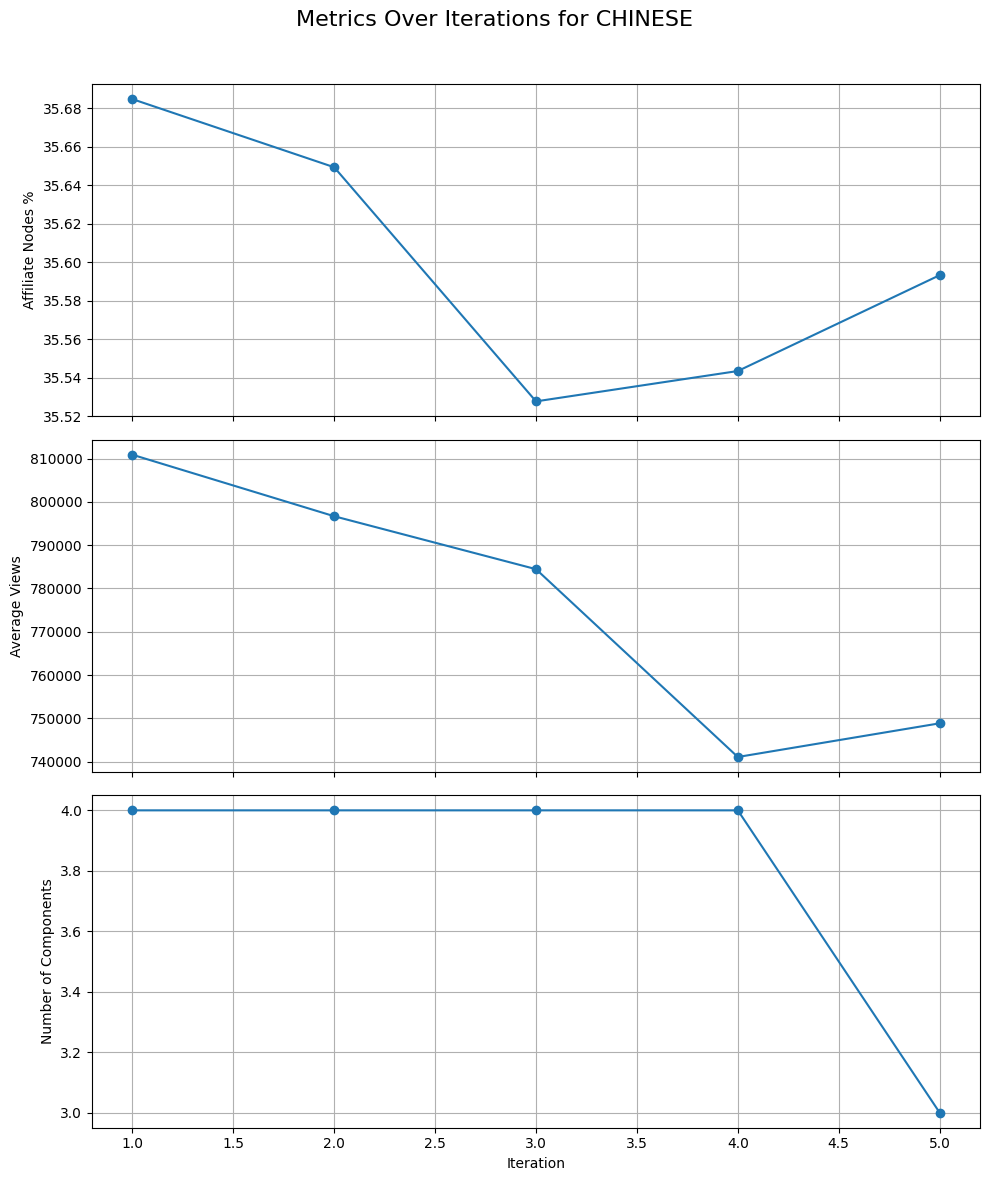

In [82]:

all_metrics = {"FRENCH": fr_metrics, "SPANISH": es_metrics, "RUSSIAN": ru_metrics, 'CHINESE': zh_metrics}

for lang, metrics in all_metrics.items():
    plot_metrics_for_single_country(all_metrics[lang], country_label=lang)

In [84]:
import matplotlib.pyplot as plt

def plot_metric_for_all_languages(all_metrics, metric_name):
    """
    Plot a given metric across iterations for multiple languages on one graph.

    Args:
        all_metrics (dict): Keys are language names, values are dicts with metrics lists.
        metric_name (str): The specific metric to plot (e.g., 'percent_affiliate').

    """
    colors = plt.cm.get_cmap('tab10').colors
    plt.figure(figsize=(10, 6))
    for i, (lang, metrics) in enumerate(all_metrics.items()):
        plt.plot(
            metrics['iteration'],
            metrics[metric_name],
            marker='o',
            label=lang,
            color=colors[i % len(colors)]
        )
    plt.title(f"{metric_name.replace('_', ' ').title()} Over Iterations")
    plt.xlabel("Iteration")
    plt.ylabel(metric_name.replace('_', ' ').title())
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

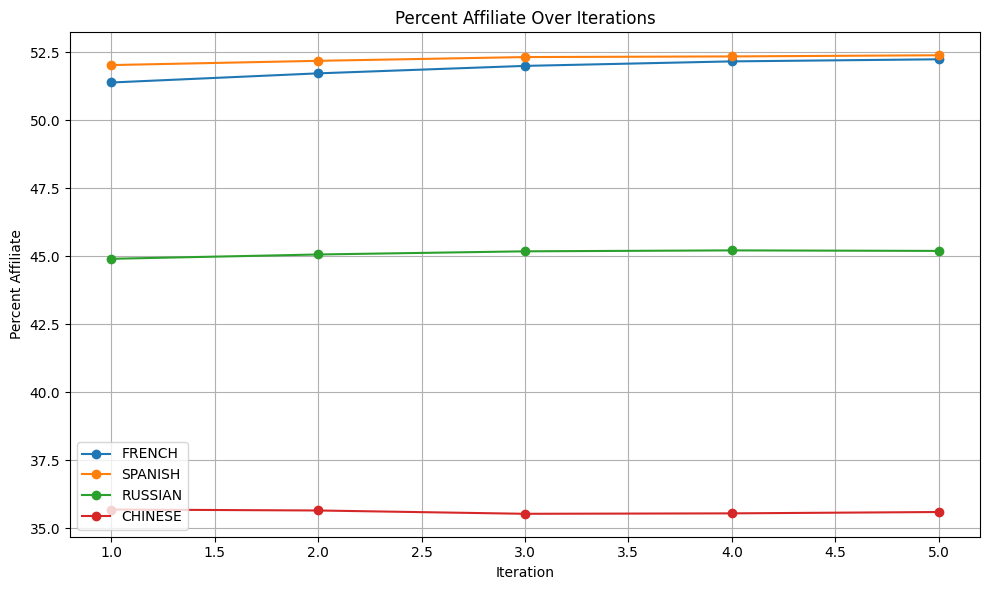

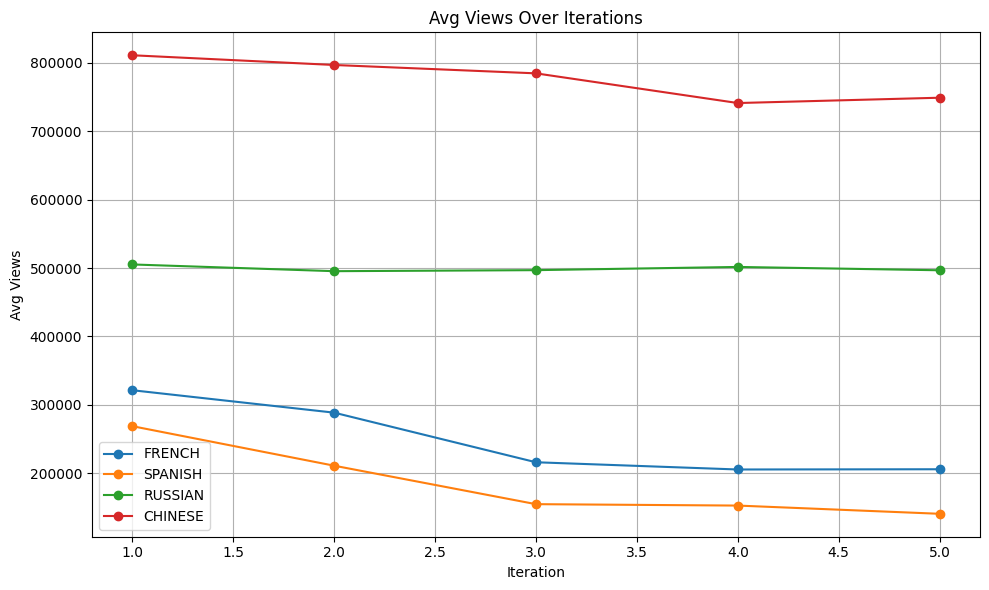

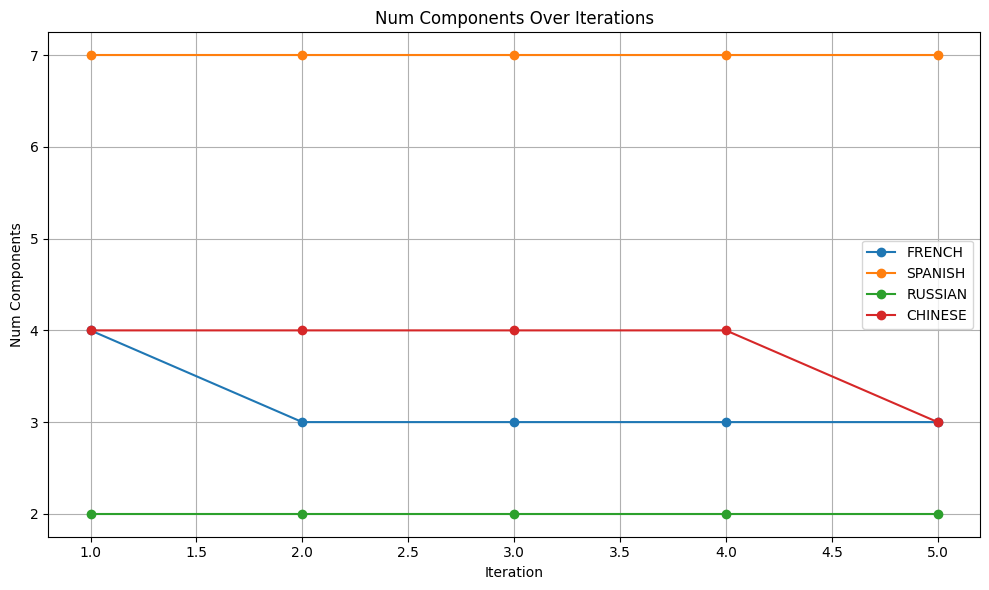

In [85]:
plot_metric_for_all_languages(all_metrics, 'percent_affiliate')
plot_metric_for_all_languages(all_metrics, 'avg_views')
plot_metric_for_all_languages(all_metrics, 'num_components')

### Community


In [15]:
#Clustering/Hierarchy:
# Modularity clustering 

# clusters = largest_cc.community_fastgreedy().as_clustering()
# print(clusters.sizes())
# membership = clusters.membership
# print(membership)
# community_list = clusters.subgraphs()

[93, 165, 210, 39, 52, 70, 69, 52, 51, 5, 81, 39, 38, 55, 104, 12, 29, 38, 53, 35, 51, 90, 34, 51, 72, 37, 43, 39, 43, 44, 87, 64, 13, 8]
[0, 0, 1, 0, 2, 0, 3, 3, 4, 4, 4, 4, 5, 4, 4, 4, 4, 6, 6, 6, 6, 6, 6, 2, 2, 7, 7, 8, 8, 8, 8, 9, 9, 6, 6, 10, 11, 11, 1, 1, 1, 1, 1, 1, 1, 8, 12, 1, 1, 1, 13, 14, 1, 11, 1, 1, 1, 8, 1, 15, 13, 1, 1, 1, 16, 17, 17, 18, 18, 18, 18, 18, 14, 10, 17, 19, 3, 10, 10, 10, 2, 13, 7, 10, 18, 10, 1, 2, 10, 2, 10, 10, 20, 10, 10, 10, 21, 22, 23, 2, 10, 10, 10, 10, 10, 10, 10, 10, 24, 10, 10, 10, 10, 10, 10, 10, 10, 0, 10, 3, 3, 1, 25, 25, 26, 26, 26, 25, 25, 25, 25, 14, 14, 14, 14, 14, 24, 24, 11, 24, 24, 24, 10, 24, 24, 24, 24, 24, 24, 14, 24, 24, 24, 24, 24, 5, 2, 14, 24, 24, 24, 24, 24, 2, 2, 2, 2, 2, 2, 2, 2, 2, 27, 2, 2, 5, 16, 1, 16, 16, 16, 16, 28, 28, 28, 28, 0, 21, 21, 29, 21, 21, 21, 1, 21, 21, 21, 21, 21, 21, 21, 20, 21, 21, 0, 26, 0, 0, 21, 0, 0, 0, 0, 0, 0, 1, 15, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 8, 8, 30, 30, 30, 30, 0, 0, 19, 19, 27, 27, 27, 5,

In [2]:
# Load edge list
twitch_edges = pd.read_csv('twitch_edges.csv', sep='|')

# Load node features
twitch_nodes = pd.read_csv('twitch_features.csv', sep='|')

big_t_g = make_graph(twitch_edges)

In [3]:
from collections import defaultdict

# Suppose your graph is `g`
g = big_t_g

# 1. Group nodes by language
language_to_nodes = defaultdict(list)
for v in g.vs:
    lang = v['language']
    language_to_nodes[lang].append(v.index)

# 2. Create subgraphs for each language community
language_communities = {}
for lang, nodes in language_to_nodes.items():
    subgraph = g.subgraph(nodes)
    language_communities[lang] = subgraph
    print(f"Language '{lang}' community: {len(nodes)} nodes, {subgraph.ecount()} edges")

# 3. Create lists of all subgraphs
community_list = language_communities.values()


Language 'FR' community: 6604 nodes, 122503 edges
Language 'ES' community: 5463 nodes, 85316 edges
Language 'ZH' community: 2718 nodes, 66892 edges
Language 'RU' community: 4618 nodes, 46153 edges


In [4]:
community_languages = ['Spanish', 'French', 'Chinese', 'Russian']

In [51]:
# Clustering based on NODE ATTRIBUTES (MATURE, AFFILIATE, VIEWS)
import numpy as np

community_features = []

for subgraph in community_list:
    views = np.array(subgraph.vs['views'])
    affiliate = np.array(subgraph.vs['affiliate'])  # 0 or 1

    # Aggregate statistics
    mean_views = views.mean() 
    affiliate_rate = affiliate.mean()  # % affiliated

    community_features.append([affiliate_rate])


In [52]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(community_features)

In [53]:
from scipy.spatial.distance import pdist, squareform

dist_vector = pdist(X_scaled, metric='euclidean')
dist_matrix = squareform(dist_vector)


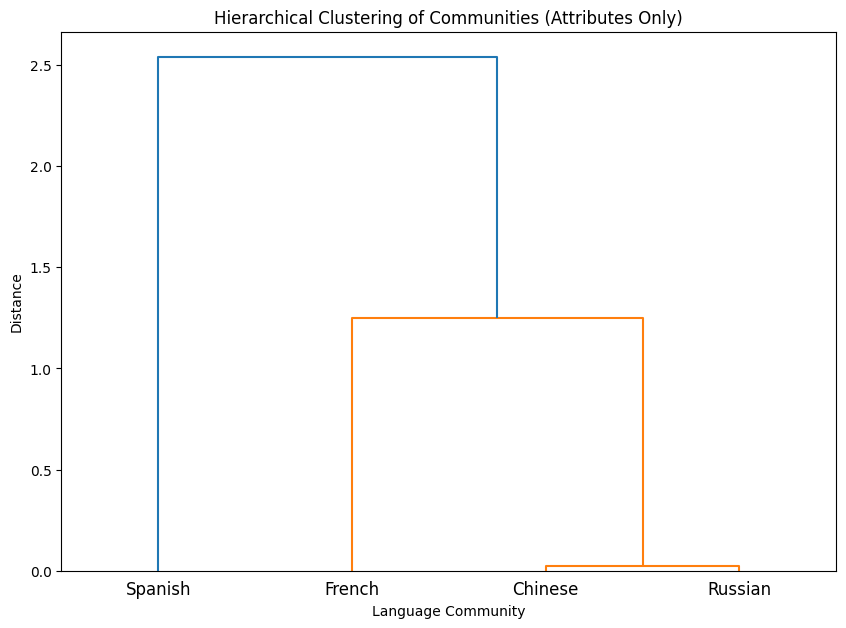

In [54]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

h_matrix = linkage(dist_vector, method='ward')  # You can also try 'average', 'complete', etc.


ddata = dendrogram(h_matrix, no_plot=True)
leaf_order = ddata['leaves']               # permutation of original indices
ordered_labels = [community_languages[i] for i in leaf_order]

plt.figure(figsize=(10, 7))
plt.title("Hierarchical Clustering of Communities (Attributes Only)")
plt.xlabel("Language Community")
plt.ylabel("Distance")
dendrogram(h_matrix, labels=ordered_labels)
plt.show()

In [6]:
# Clustering based on NODE STRUCTURE (DENSITY, DEGREE, SIZE)
import numpy as np

structural_features = []

for subgraph in community_list:
    avg_degree = np.mean(subgraph.degree())
    density = subgraph.density()

    structural_features.append([density, avg_degree])


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_struct_scaled = scaler.fit_transform(structural_features)


In [8]:
from scipy.spatial.distance import pdist, squareform

dist_vector = pdist(X_struct_scaled, metric='euclidean')
dist_matrix = squareform(dist_vector)


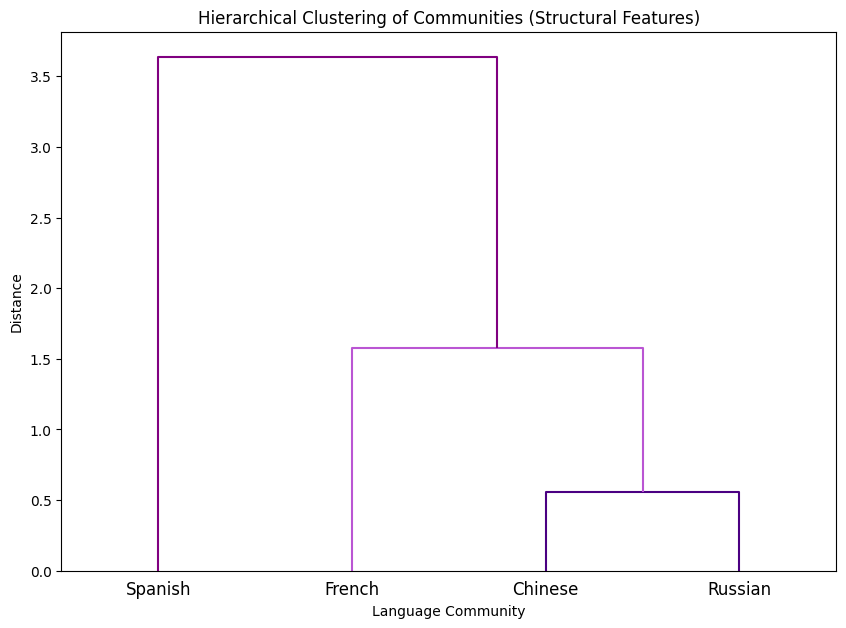

In [21]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
import numpy as np

# Define cool colors (you can customize these)
cool_colors = ['#4B0082', '#BA55D3','#800080', '#9932CC']

def cool_link_color_func(k):
    # Map cluster ids to cool colors cyclically
    return cool_colors[k % len(cool_colors)]

# Generate dendrogram as before, but with custom colors
h_matrix = linkage(dist_vector, method='ward')
ddata = dendrogram(h_matrix, no_plot=True)
leaf_order = ddata['leaves']
ordered_labels = [community_languages[i] for i in leaf_order]

plt.figure(figsize=(10, 7))
plt.title("Hierarchical Clustering of Communities (Structural Features)")
plt.xlabel("Language Community")
plt.ylabel("Distance")

dendrogram(h_matrix, labels=ordered_labels, link_color_func=cool_link_color_func)

plt.show()
